# Práctica 2 · Trading con aprendizaje por refuerzo: algoritmo DQN

Esta libreta resuelve la parte de **DQN** de la práctica 2 (la parte de A3C la realiza otro miembro del grupo). Es la continuación de la práctica 1, así que se reutilizan **sin modificaciones** el entorno `SimpleTradingEnv`, las cuatro funciones generadoras de precios y, sobre todo, **el mismo protocolo de evaluación** (mismas series de validación y de test, mismas métricas, mismas referencias y mismo criterio de convergencia). El código compartido está en `../trader_rl.py`. Así, los resultados de DQN se pueden comparar directamente con los de Q-Learning, SARSA y Monte Carlo de la práctica 1 (`../tabla_comparativa.csv`).

**Qué pide el enunciado y dónde se responde**

| Ejercicio | Dónde |
|---|---|
| 1. Implementar DQN y probarlo con las cuatro funciones de precios, una serie nueva en cada episodio, y evaluar en series de test nuevas | secciones 2–5 y 7 |
| 2. Analizar las soluciones y compararlas con el agente aleatorio y con *buy & hold*; ¿es la estrategia la esperada? | secciones 7 y 8 |
| 3. Ajustar hiperparámetros: $\alpha$ (aquí, la tasa de aprendizaje de la red), $\epsilon$, $\gamma$ y nº de episodios | sección 6 |
| 4. Tabla comparativa con *baselines*: rendimiento y tiempo de convergencia | sección 7 |

**Más allá de los mínimos** (diapositivas «Doble DQN y DQN en duelo» del profesor): Doble DQN, DQN en duelo y su combinación; ablación de la red objetivo; medida de la sobreestimación de $Q$; sensibilidad al periodo de copia de la red objetivo; un estado ampliado que la red puede usar sin discretizar; y comparación con los algoritmos tabulares de la práctica 1.

**Contenido**

1. Configuración y recordatorio del entorno
2. Preparar el estado y la recompensa para la red
3. El algoritmo DQN y sus variantes
4. Primer entrenamiento (comprobación)
5. Protocolo de evaluación y *baselines*
6. Ajuste de hiperparámetros
7. Entrenamiento final, curvas de aprendizaje y resultados en test
8. Análisis: política aprendida, sobreestimación, estado ampliado
9. Conclusiones y limitaciones

**Requisitos:** Python ≥ 3.10 con `torch`, `gymnasium`, `numpy`, `pandas`, `matplotlib` y `joblib`. Los resultados costosos se guardan en `cache_dqn/` y las figuras en `figuras_dqn/`; con `RECOMPUTE = False` (valor por defecto) se cargan sin volver a entrenar.

## 1. Configuración y recordatorio del entorno

In [1]:
import os
import sys
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from joblib import Parallel, delayed, dump, load
from IPython.display import display

warnings.filterwarnings("ignore")
torch.set_num_threads(1)           # la red es pequeña: un hilo por proceso y paralelizamos entre entrenamientos

# trader_rl.py (práctica 1) está en la carpeta superior: lo añadimos a la ruta también para los procesos hijos de joblib
PADRE = str(Path.cwd().parent)
sys.path.insert(0, PADRE)
os.environ["PYTHONPATH"] = PADRE + os.pathsep + os.environ.get("PYTHONPATH", "")

from trader_rl import (GENERATORS, SimpleTradingEnv, ExtendedTradingEnv, make_series, test_sets, N_STEPS, N_VAL, N_TEST,
                       SEED_TRAIN, SEED_CALIB, SEED_VAL, SEED_TEST, evaluate, run_episode, BASELINES, summarize, convergence_episode)

GENS = list(GENERATORS)
CACHE, FIGS = Path("cache_dqn"), Path("figuras_dqn")
CACHE.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False      # True: vuelve a entrenarlo todo (unos 25-30 min en un portátil con 16 hilos); False: carga cache_dqn/
MODO_RAPIDO = False    # True: presupuesto minúsculo, solo para comprobar que la libreta corre de punta a punta
N_JOBS = max(1, min(12, os.cpu_count() or 1))

# Presupuesto de entrenamiento
N_CONFIGS, N_EP_BUSQUEDA, EVAL_BUSQUEDA, SEMILLAS_BUSQUEDA = 10, 100, 20, (100, 101)   # búsqueda aleatoria (corta)
TOP_K, SEMILLAS_REEVAL = 2, (200, 201)                                                  # reevaluación con entrenamiento completo
N_EP_FINAL, EVAL_CADA, SEMILLAS_FINAL = 200, 20, (0, 1, 2, 3, 4)                         # entrenamiento final (5 semillas)
SEMILLAS_EXTRA = (300, 301)                                                        # experimentos adicionales
if MODO_RAPIDO:
    N_CONFIGS, N_EP_BUSQUEDA, EVAL_BUSQUEDA, SEMILLAS_BUSQUEDA = 3, 10, 5, (100,)
    TOP_K, SEMILLAS_REEVAL, N_EP_FINAL, EVAL_CADA, SEMILLAS_FINAL, SEMILLAS_EXTRA = 2, (200,), 12, 4, (0, 1), (300,)
    RECOMPUTE, CACHE = True, Path("cache_dqn_rapido")
    CACHE.mkdir(exist_ok=True)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
print(f"torch {torch.__version__} | {N_JOBS} procesos | RECOMPUTE={RECOMPUTE} | MODO_RAPIDO={MODO_RAPIDO}")

torch 2.15.0+cpu | 12 procesos | RECOMPUTE=False | MODO_RAPIDO=False


**El entorno** es exactamente el del enunciado (el de la práctica 1):

- **Estado:** `(tendencia, posición)`. La tendencia es $(p_t - \bar p_{t-5:t})/\bar p_{t-5:t}$ (precio actual frente a la media de los últimos 6 precios), recortada a $[-1,1]$; la posición es 1 si se tiene el activo y 0 si no.
- **Acciones:** 0 = vender, 1 = mantener, 2 = comprar. Vender solo tiene efecto si se tiene el activo, y comprar solo si no se tiene.
- **Recompensa:** el cambio relativo del precio mientras se mantiene la posición, menos un 0,1 % de comisión en cada compra o venta. Se actúa al precio anterior, así que no hay información del futuro.
- **Episodio:** una serie de 500 precios (494 pasos de decisión). Capital inicial de 1000.

**Protocolo de datos** (el de la práctica 1; los rangos de semillas son disjuntos, así que ninguna serie se reutiliza entre conjuntos):

,conjunto,series,semillas de las series,para qué
0,entrenamiento,1 nueva por episodio (200 episodios por entren...,0 + 10 000·semilla + episodio,aprender
1,calibración (escalas),40,100000 + i,normalizar la entrada de la red
2,validación,30 (siempre las mismas),500000 + i,elegir hiperparámetros y dibujar curvas
3,test,100 (siempre las mismas),900000 + i,evaluación final (no se usa para ajustar nada)


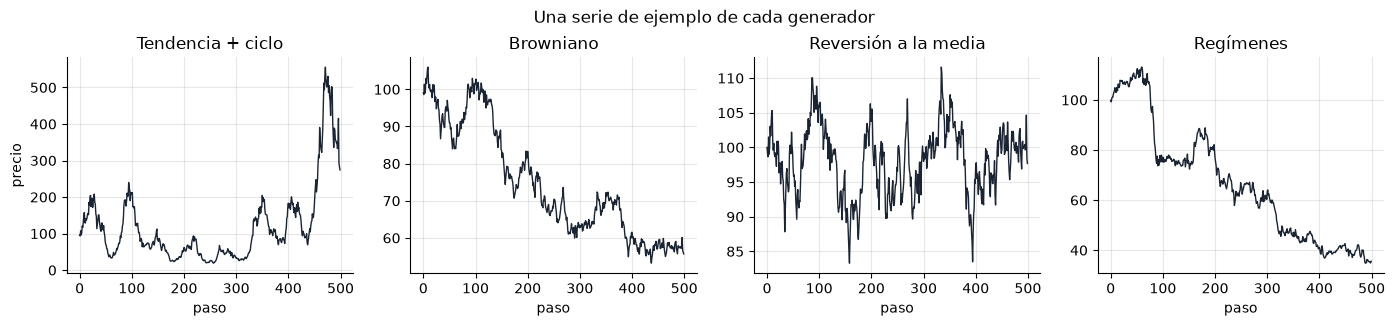

In [2]:
protocolo = pd.DataFrame({
    "conjunto": ["entrenamiento", "calibración (escalas)", "validación", "test"],
    "series": [f"1 nueva por episodio ({N_EP_FINAL} episodios por entrenamiento)", "40", f"{N_VAL} (siempre las mismas)", f"{N_TEST} (siempre las mismas)"],
    "semillas de las series": [f"{SEED_TRAIN} + 10 000·semilla + episodio", f"{SEED_CALIB} + i", f"{SEED_VAL} + i", f"{SEED_TEST} + i"],
    "para qué": ["aprender", "normalizar la entrada de la red", "elegir hiperparámetros y dibujar curvas", "evaluación final (no se usa para ajustar nada)"]})
display(protocolo)

fig, axs = plt.subplots(1, 4, figsize=(17, 2.8))
for ax, g in zip(axs, GENS):
    ax.plot(make_series(g, SEED_VAL), color="#1b2433", lw=1)
    ax.set_title(g)
    ax.set_xlabel("paso")
axs[0].set_ylabel("precio")
fig.suptitle("Una serie de ejemplo de cada generador", y=1.05)
plt.show()

## 2. Preparar el estado y la recompensa para la red

En la práctica 1 la tendencia se discretizaba con cuantiles. Una red neuronal admite entradas continuas, así que **no hace falta discretizar**, pero sí **normalizar**: la tendencia vive en rangos muy distintos según el mercado (en torno a ±0,3 en *tendencia + ciclo* y ±0,03 en los demás), y una red entrenada con descenso de gradiente aprende mal con entradas de escalas tan dispares.

Decisiones:

- **Entrada de la red:** `[(tendencia − media) / desviación, posición]`, con la media y la desviación calculadas **por mercado** en 40 series de calibración (semillas disjuntas de las de entrenamiento, validación y test). Se recorta a $\pm 5$ desviaciones.
- **Recompensa:** se divide por la desviación típica del retorno por paso de cada mercado. Es una constante positiva, así que **no cambia qué política es óptima**, pero deja los objetivos de la red en una escala ~1 en todos los mercados. Esto evita que *tendencia + ciclo* (ruido del 10 % por paso) y el resto (1–2 %) necesiten tasas de aprendizaje distintas solo por la escala.
- **Acciones válidas:** sin activo solo se consideran {mantener, comprar} y con activo {vender, mantener}, porque las otras no tienen efecto (es lo mismo que se hizo en SARSA). Se enmascaran al elegir la acción y al calcular el valor del estado siguiente, de modo que la red no desperdicia capacidad en acciones redundantes.

In [3]:
VALIDAS = np.array([[False, True, True],      # sin activo: mantener o comprar
                    [True, True, False]])     # con activo: vender o mantener
VALIDAS_T = torch.from_numpy(VALIDAS)


def calibrar(gen, env_cls=SimpleTradingEnv, n_series=40):
    """Media y desviación de cada componente de la observación, y desviación de la recompensa por paso (series de calibración)."""
    obs, rets = [], []
    for i in range(n_series):
        p = make_series(gen, SEED_CALIB + i)
        env = env_cls(p)
        o, _ = env.reset()
        done = False
        while not done:
            obs.append(o)
            o, _, done, _, _ = env.step(1)
        rets.append(p[1:] / p[:-1] - 1)
    obs = np.array(obs, dtype=np.float64)
    mu, sd = obs.mean(0), obs.std(0)
    mu[1], sd[1] = 0.0, 1.0                          # la posición (0/1) no se normaliza
    return mu.astype(np.float32), sd.astype(np.float32), float(np.std(np.concatenate(rets)))


ESCALAS = {g: calibrar(g) for g in GENS}
display(pd.DataFrame({g: {"media de la tendencia": ESCALAS[g][0][0], "desviación de la tendencia": ESCALAS[g][1][0],
                          "desviación de la recompensa por paso": ESCALAS[g][2]} for g in GENS}).T.round(4))

,media de la tendencia,desviación de la tendencia,desviación de la recompensa por paso
Tendencia + ciclo,0.0222,0.1533,0.1063
Browniano,-0.0001,0.0250,0.0201
Reversión a la media,0.0001,0.0245,0.0205
Regímenes,-0.0005,0.0231,0.0186


## 3. El algoritmo DQN y sus variantes

**DQN** (*Deep Q-Network*) es Q-Learning en el que la tabla $Q(s,a)$ se sustituye por una **red neuronal** $Q_\theta(s,a)$. Como la red generaliza entre estados parecidos, no necesita una fila por cada estado. A cambio, el aprendizaje se vuelve menos estable (los datos están correlacionados y el objetivo se mueve mientras se aprende). DQN lo resuelve con dos ingredientes:

1. **Memoria de experiencias** (*replay buffer*): cada transición $(s,a,r,s',\text{fin})$ se guarda, y en cada actualización se entrena con un **lote aleatorio** de la memoria. Así se rompe la correlación entre pasos consecutivos y cada experiencia se reutiliza muchas veces.
2. **Objetivo** $Y_t = r_t + \gamma \max_{a'} Q(s_{t+1}, a')$ y pérdida $(Y_t - Q_\theta(s_t,a_t))^2$. Usamos la pérdida de Huber (cuadrática para errores pequeños y lineal para los grandes), que es más robusta al ruido de las recompensas.

**Variantes de las diapositivas del profesor**

| Variante | Qué cambia |
|---|---|
| **DQN** (la «ecuación básica») | $Y_t = r_t + \gamma \max_{a'} Q(s_{t+1},a')$ con la misma red $Q$. El operador $\max$ tiende a **sobreestimar** $Q$. |
| **Doble DQN** | Dos redes, $Q$ y $Q'$. $Q$ **elige** la acción, $Q'$ la **evalúa**: $a^* = \arg\max_{a'} Q(s_{t+1},a')$ y $Y_t = r_t + \gamma\, Q'(s_{t+1}, a^*)$. $Q$ se actualiza en cada paso de entrenamiento y $Q'$ es una copia de $Q$ que se refresca cada $k$ pasos. |
| **DQN en duelo** | Cambia la **arquitectura**: la red estima por separado el valor del estado $V(s)$ y la ventaja de cada acción $A(s,a)$, y los combina: $Q(s,a) = V(s) + A(s,a) - \text{media}_{a'}A(s,a')$. |
| *(ablación)* **DQN + red objetivo** | El objetivo usa la copia lenta $Q'$ con el $\max$ habitual: $Y_t = r_t + \gamma \max_{a'} Q'(s_{t+1},a')$. Separa el efecto de «tener una red objetivo» del de «elegir y evaluar con redes distintas». |

**Decisiones de implementación**

- **Red:** perceptrón multicapa con 2 capas ocultas ReLU y 3 salidas (una por acción). En la variante en duelo, la capa final se divide en una neurona $V(s)$ y tres $A(s,a)$.
- **Exploración $\epsilon$-greedy** con el mismo calendario que en la práctica 1: $\epsilon$ baja geométricamente de 1 a `eps_final` durante una fracción `eps_frac` de los episodios. Al evaluar se usa la política *greedy*; los empates se rompen a favor de **mantener**.
- **Tasa de aprendizaje decreciente** (Adam, de `lr` a `lr·lr_final`): en la práctica 1 el hallazgo más claro fue que un $\alpha$ pequeño y decreciente era la decisión crítica, porque la recompensa de cada paso es casi todo ruido.
- **Una actualización cada 4 pasos** con un lote de `batch` transiciones (tras un *warm-up* de 2000 transiciones llenando la memoria con la política casi aleatoria del principio). Memoria de 50 000 transiciones, que son unos 100 episodios.
- **Rapidez:** para elegir la acción durante el entrenamiento se usa una copia numpy de los pesos que *comparte memoria* con la red de PyTorch (siempre está al día), porque una pasada hacia delante de una red tan pequeña es mucho más rápida en numpy que llamando a PyTorch en cada paso.

In [4]:
class RedQ(nn.Module):
    """Perceptrón multicapa con 2 capas ocultas. Con dueling=True la salida se parte en V(s) y A(s,a)."""

    def __init__(self, n_in=2, hidden=64, dueling=False):
        super().__init__()
        self.dueling = dueling
        self.cuerpo = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        if dueling:
            self.v, self.a = nn.Linear(hidden, 1), nn.Linear(hidden, 3)
        else:
            self.q = nn.Linear(hidden, 3)

    def forward(self, x):
        h = self.cuerpo(x)
        if self.dueling:
            a = self.a(h)
            return self.v(h) + a - a.mean(dim=1, keepdim=True)     # Q = V + A - media(A)
        return self.q(h)

    def capas_numpy(self):
        """Vistas numpy de los pesos: comparten memoria con la red, así que siempre están actualizadas."""
        L = [(m.weight.detach().numpy(), m.bias.detach().numpy()) for m in self.cuerpo if isinstance(m, nn.Linear)]
        salida = (self.v, self.a) if self.dueling else (self.q,)
        return L + [(m.weight.detach().numpy(), m.bias.detach().numpy()) for m in salida]


def q_numpy(x, capas, dueling):
    """Misma red que RedQ.forward, para un solo estado y en numpy (mucho más rápido que PyTorch para un vector)."""
    h = np.maximum(capas[0][0] @ x + capas[0][1], 0)
    h = np.maximum(capas[1][0] @ h + capas[1][1], 0)
    if dueling:
        v, a = capas[2][0] @ h + capas[2][1], capas[3][0] @ h + capas[3][1]
        return v + a - a.mean()
    return capas[2][0] @ h + capas[2][1]


class PoliticaDQN:
    """Política greedy de una red ya entrenada (pesos copiados). Compara solo las acciones válidas; los empates, a mantener."""

    def __init__(self, capas, dueling, mu, sd):
        self.capas, self.dueling, self.mu, self.sd = [(W.copy(), b.copy()) for W, b in capas], dueling, mu, sd

    def q(self, obs):
        x = np.clip((np.asarray(obs, dtype=np.float32) - self.mu) / self.sd, -5, 5)
        return q_numpy(x, self.capas, self.dueling)

    def __call__(self, obs):
        q = self.q(obs)
        if obs[1] < 0.5:                      # sin activo: mantener o comprar
            return 2 if q[2] > q[1] else 1
        return 0 if q[0] > q[1] else 1        # con activo: vender o mantener

In [5]:
class AgenteDQN:
    """DQN con memoria de experiencias. `objetivo` elige cómo se calcula Y_t:
         'online' -> max_a' Q(s',a')  (ecuación básica)        'target' -> max_a' Q'(s',a')  (red objetivo)
         'double' -> Q'(s', argmax_a' Q(s',a'))  (Doble DQN)   `dueling` cambia la arquitectura de la red."""

    def __init__(self, mu, sd, s_rew, gamma=0.9, lr=3e-4, lr_final=0.1, hidden=64, batch=128, buffer=50_000, cada=4,
                 target_every=1000, warmup=2000, eps_final=0.05, eps_frac=0.5, objetivo="online", dueling=False, seed=0):
        torch.manual_seed(seed)
        self.rng = np.random.default_rng(seed)
        self.mu, self.sd, self.s_rew = mu, sd, s_rew
        self.gamma, self.batch, self.cada, self.target_every, self.warmup = gamma, batch, cada, target_every, warmup
        self.eps_final, self.eps_frac, self.objetivo, self.dueling = eps_final, eps_frac, objetivo, dueling
        self.red = RedQ(len(mu), hidden, dueling)
        self.capas = self.red.capas_numpy()
        self.lr, self.lr_final = lr, lr_final
        try:
            self.opt = torch.optim.Adam(self.red.parameters(), lr=lr, fused=True)
        except Exception:
            self.opt = torch.optim.Adam(self.red.parameters(), lr=lr)
        self.target = None
        if objetivo in ("target", "double"):
            self.target = RedQ(len(mu), hidden, dueling)
            self.target.load_state_dict(self.red.state_dict())
        d = len(mu)
        self.S, self.S2 = np.zeros((buffer, d), np.float32), np.zeros((buffer, d), np.float32)
        self.A, self.R, self.D = np.zeros(buffer, np.int64), np.zeros(buffer, np.float32), np.zeros(buffer, np.float32)
        self.n, self.cap, self.pasos, self.q_log = 0, buffer, 0, []

    # --- calendarios (los mismos que en la práctica 1 para ε) ---
    def epsilon(self, ep, n_ep):
        return self.eps_final ** min(1.0, ep / max(1.0, self.eps_frac * n_ep))

    def fijar_lr(self, ep, n_ep):
        for g in self.opt.param_groups:
            g["lr"] = self.lr * self.lr_final ** (ep / max(1, n_ep - 1))

    # --- interacción ---
    def features(self, obs):
        return np.clip((obs - self.mu) / self.sd, -5, 5).astype(np.float32)

    def actuar(self, x, eps):
        pos = int(x[1])
        if self.rng.random() < eps:                                   # exploración: al azar entre las acciones válidas
            return (1, 2)[int(self.rng.integers(2))] if pos == 0 else (1, 0)[int(self.rng.integers(2))]
        q = q_numpy(x, self.capas, self.dueling)                      # explotación: greedy entre las válidas
        if pos == 0:
            return 2 if q[2] > q[1] else 1
        return 0 if q[0] > q[1] else 1

    def guardar(self, x, a, r, x2, fin):
        i = self.n % self.cap
        self.S[i], self.A[i], self.R[i], self.S2[i], self.D[i] = x, a, r / self.s_rew, x2, float(fin)
        self.n += 1
        self.pasos += 1
        if self.n >= self.warmup and self.pasos % self.cada == 0:
            self.actualizar()
        if self.target is not None and self.pasos % self.target_every == 0:
            self.target.load_state_dict(self.red.state_dict())        # Q' <- Q cada k pasos

    # --- un paso de descenso de gradiente sobre un lote de la memoria ---
    def actualizar(self):
        idx = self.rng.integers(0, min(self.n, self.cap), self.batch)
        s, a, r = torch.from_numpy(self.S[idx]), torch.from_numpy(self.A[idx]), torch.from_numpy(self.R[idx])
        s2, fin = torch.from_numpy(self.S2[idx]), torch.from_numpy(self.D[idx])
        q = self.red(s).gather(1, a[:, None]).squeeze(1)              # Q(s_t, a_t)
        with torch.no_grad():
            valido = VALIDAS_T[s2[:, 1].long()]                       # acciones con efecto en el estado siguiente
            if self.objetivo == "online":
                qn = self.red(s2).masked_fill(~valido, -1e9).max(1).values
            elif self.objetivo == "target":
                qn = self.target(s2).masked_fill(~valido, -1e9).max(1).values
            else:                                                     # Doble DQN: Q elige, Q' evalúa
                a2 = self.red(s2).masked_fill(~valido, -1e9).argmax(1, keepdim=True)
                qn = self.target(s2).gather(1, a2).squeeze(1)
            y = r + self.gamma * (1 - fin) * qn                       # Y_t (en el último paso no hay estado siguiente)
            self.q_log.append(float(qn.mean()))                       # diagnóstico: valor medio estimado del estado siguiente
        loss = F.smooth_l1_loss(q, y)
        self.opt.zero_grad(set_to_none=True)
        loss.backward()
        self.opt.step()

    def politica(self):
        return PoliticaDQN(self.capas, self.dueling, self.mu, self.sd)

    def exportar(self):
        """Pesos y escalas, sin objetos de PyTorch: se pueden guardar y mandar entre procesos."""
        return {"capas": [(W.copy(), b.copy()) for W, b in self.capas], "dueling": self.dueling, "mu": self.mu, "sd": self.sd}


def politica_desde(exp):
    return PoliticaDQN(exp["capas"], exp["dueling"], exp["mu"], exp["sd"])


VARIANTES = {
    "DQN": dict(objetivo="online", dueling=False),
    "DQN + red objetivo": dict(objetivo="target", dueling=False),
    "Doble DQN": dict(objetivo="double", dueling=False),
    "DQN en duelo": dict(objetivo="online", dueling=True),
    "Doble DQN en duelo": dict(objetivo="double", dueling=True),
}

**Bucle de entrenamiento.** Cada episodio usa una **serie nueva** del mismo generador (semilla distinta en cada episodio y en cada entrenamiento). Cada `eval_cada` episodios se evalúa la política *greedy* en las 30 series de validación; esa curva sirve para ajustar hiperparámetros y para medir la convergencia, igual que en la práctica 1.

In [6]:
def entrenar(gen, params, n_episodios, semilla, val_series=None, eval_cada=20, escalas=None, env_cls=SimpleTradingEnv):
    mu, sd, s_rew = escalas if escalas else calibrar(gen, env_cls)
    ag = AgenteDQN(mu, sd, s_rew, seed=semilla, **params)
    hist = {"ep": [], "val": [], "val_ops": [], "recompensa": [], "q": [], "t_ep": []}

    def validar(ep):
        res = evaluate(val_series, lambda i, p=ag.politica(): p, env_cls)
        hist["ep"].append(ep)
        hist["val"].append(float(res["log_ret"].mean()))
        hist["val_ops"].append(float(res["trades"].mean()))

    if val_series is not None:
        validar(0)                                        # política sin entrenar
    for ep in range(n_episodios):
        t0 = time.perf_counter()
        env = env_cls(make_series(gen, SEED_TRAIN + 10_000 * semilla + ep))
        obs, _ = env.reset()
        ag.fijar_lr(ep, n_episodios)
        x, fin, eps, total, n_q = ag.features(obs), False, ag.epsilon(ep, n_episodios), 0.0, len(ag.q_log)
        while not fin:
            a = ag.actuar(x, eps)
            obs, r, fin, _, _ = env.step(a)
            x2 = ag.features(obs)
            ag.guardar(x, a, r, x2, fin)
            x, total = x2, total + r
        hist["recompensa"].append(total)
        hist["q"].append(float(np.mean(ag.q_log[n_q:])) if len(ag.q_log) > n_q else np.nan)
        hist["t_ep"].append(time.perf_counter() - t0)
        if val_series is not None and ((ep + 1) % eval_cada == 0 or ep + 1 == n_episodios):
            validar(ep + 1)
    return ag, hist

## 4. Primer entrenamiento (comprobación)

Antes de ajustar nada, comprobamos que el agente aprende. Entrenamos un DQN con hiperparámetros razonables (sin ajustar) en *tendencia + ciclo* (el mercado con una señal clara de *momentum*) y en *reversión a la media*. La línea discontinua es el log-retorno de *buy & hold* en las series de validación y la punteada, el de no operar nunca.

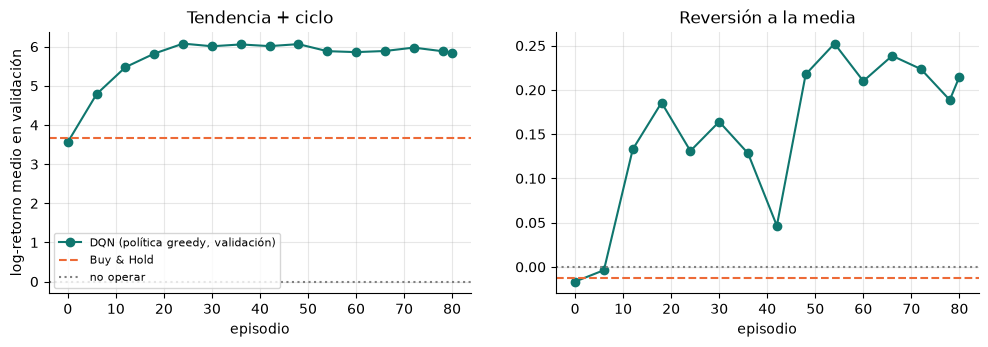

160 episodios en 35 s


In [7]:
def val_series(gen):
    return [make_series(gen, SEED_VAL + i) for i in range(N_VAL)]


def prueba(gen, n_ep):
    val = val_series(gen)
    ag, h = entrenar(gen, dict(gamma=0.9, lr=3e-4, lr_final=0.1, eps_frac=0.5), n_ep, 0, val, max(1, n_ep // 12), ESCALAS[gen])
    bh = evaluate(val, BASELINES["Buy & Hold"])["log_ret"].mean()
    return h, bh


n_prueba = 12 if MODO_RAPIDO else 80
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
t0 = time.perf_counter()
for ax, g in zip(axs, ["Tendencia + ciclo", "Reversión a la media"]):
    h, bh = prueba(g, n_prueba)
    ax.plot(h["ep"], h["val"], "o-", color="#0f766e", label="DQN (política greedy, validación)")
    ax.axhline(bh, color="#ed6a37", ls="--", label="Buy & Hold")
    ax.axhline(0, color="gray", ls=":", label="no operar")
    ax.set_title(g)
    ax.set_xlabel("episodio")
axs[0].set_ylabel("log-retorno medio en validación")
axs[0].legend(fontsize=8)
plt.show()
print(f"{2 * n_prueba} episodios en {time.perf_counter() - t0:.0f} s")

### Qué esperamos antes de ajustar nada

Con lo aprendido en la práctica 1 y con la teoría de las diapositivas, estas son las hipótesis que se contrastarán con los resultados (sección 9):

1. **Tendencia + ciclo** (señal fuerte de *momentum*): DQN debería aprender el mismo *momentum* con histéresis que los algoritmos tabulares y empatar con ellos. Además debería **aprender en muchos menos episodios**, porque la red generaliza entre tendencias parecidas, mientras que la tabla tiene que visitar cada intervalo.
2. **Reversión a la media** (señal débil, estrategia *contrarian*): la señal es de décimas de punto frente a un ruido del 1–2 % por paso, y el objetivo de DQN se apoya en sus propias estimaciones (*bootstrapping*) con una red que cambia a cada paso. Esperamos que aprenda, pero con una curva **inestable**: la política puede «apagarse» (dejar de operar) durante unos episodios.
3. **Browniano y regímenes** (sin señal, o señal escondida en las colas de la tendencia): lo racional es no operar, o casi. Una red tiene mucha más capacidad que una tabla de 10–20 intervalos, así que hay riesgo de **sobreajustar al ruido y operar de más**.
4. **Variantes:** Doble DQN debería ayudar donde más pesa la sobreestimación (descuento alto y señal débil). El DQN en duelo debería aportar poco: aquí solo hay 3 acciones y 2 con efecto en cada estado, y su ventaja aparece cuando muchas acciones tienen valores parecidos.
5. **Tiempo:** DQN necesitará menos episodios, pero cada uno cuesta bastante más que en una tabla (una actualización de red cada 4 pasos); el tiempo hasta converger **en segundos** puede ser peor que el de los algoritmos tabulares.

## 5. Protocolo de evaluación y *baselines*

Se usa **exactamente el de la práctica 1** (`trader_rl.py`):

- Cada política se ejecuta, **sin explorar**, sobre las mismas 100 series de test de cada mercado, que no se han usado para entrenar ni para elegir nada.
- **Métrica principal: log-retorno medio** del capital, $\overline{\ln(B_T/B_0)}$, que equivale al crecimiento geométrico del capital. Se prefiere a la media del balance porque en *tendencia + ciclo* los capitales finales llegan a multiplicarse por cientos y unas pocas series dominarían la media. También se dan el retorno geométrico, el Sharpe, el *drawdown* máximo, el número de operaciones y el % de series en las que se gana a *buy & hold*.
- **Referencias:** agente aleatorio, *buy & hold*, no operar nunca y dos reglas fijas (*momentum*: dentro si la tendencia es positiva; *contrarian*: dentro si es negativa).
- **Convergencia:** el primer episodio a partir del cual la curva de validación (suavizada) ya no sale de una banda alrededor de su valor final. El tiempo en segundos es ese nº de episodios por el coste medio de un episodio, medido en serie y en el mismo ordenador.

In [8]:
TEST = test_sets()
res_base, filas = {}, []
for g in GENS:
    for nombre, fabrica in BASELINES.items():
        res = evaluate(TEST[g], fabrica)
        res_base[(g, nombre)] = res
        filas.append(summarize(res, nombre, g))
base = pd.DataFrame(filas).set_index(["Generador", "Agente"])
display(base[["Log-ret. medio", "Ret. geométrico (%)", "Sharpe", "Max DD (%)", "Operaciones"]].round(3))

# Comprobación: con las mismas semillas, las referencias son idénticas a las de la práctica 1
prac1 = pd.read_csv(Path(PADRE) / "tabla_comparativa.csv").set_index(["Generador", "Agente"])
assert np.allclose(base["Log-ret. medio"], prac1.loc[base.index, "Log-ret. medio"], atol=1e-3), "las series de test no coinciden con las de la práctica 1"   # el CSV guarda 4 decimales
print("OK: las referencias coinciden con las de la práctica 1 (mismas series de test).")

Log-ret. medio  Ret. geométrico (%)  \
Generador            Agente                                                    
Tendencia + ciclo    Aleatorio                    1.558              375.064   
                     Buy & Hold                   3.316             2655.989   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)             6.105            44704.614   
                     Contrarian (regla)          -2.973              -94.883   
Browniano            Aleatorio                   -0.187              -17.058   
                     Buy & Hold                  -0.062               -6.039   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.141              -13.135   
                     Contrarian (regla)          -0.159              -14.695   
Reversión a la media Aleatorio                   -0.169              -15.581   
                     Buy & Hold                  -0.005               -0.484   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.324              -27.707   
                     Contrarian (regla)           0.069                7.096   
Regímenes            Aleatorio                   -0.220              -19.734   
                     Buy & Hold                  -0.128              -11.981   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.126              -11.877   
                     Contrarian (regla)          -0.233              -20.796   

                                         Sharpe  Max DD (%)  Operaciones  
Generador            Agente                                               
Tendencia + ciclo    Aleatorio            1.270      80.419       164.26  
                     Buy & Hold           1.856      90.251         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)     3.098      60.429        92.59  
                     Contrarian (regla)  -0.772      95.330        92.37  
Browniano            Aleatorio           -0.311      36.044       164.26  
                     Buy & Hold           0.057      41.919         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)    -0.241      34.717       119.16  
                     Contrarian (regla)  -0.232      34.226       119.18  
Reversión a la media Aleatorio           -0.262      31.895       164.26  
                     Buy & Hold           0.154      25.678         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)    -0.627      36.937       125.95  
                     Contrarian (regla)   0.263      23.624       125.95  
Regímenes            Aleatorio           -0.423      35.366       164.26  
                     Buy & Hold          -0.043      43.733         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)    -0.225      32.118       116.54  
                     Contrarian (regla)  -0.405      36.555       116.30

OK: las referencias coinciden con las de la práctica 1 (mismas series de test).


## 6. Ajuste de hiperparámetros

Se ajustan **por separado para cada mercado** y **solo con las series de validación**; las de test no se tocan hasta la sección 7. El criterio es el log-retorno medio en validación de la política *greedy*. Como en la práctica 1 vimos que la curva de aprendizaje oscila (a veces la política «se apaga» y deja de operar durante unos episodios), la puntuación de un entrenamiento es **la media de sus tres últimas evaluaciones**, no solo la última: así no se premia a una configuración por haber acertado el último punto por azar.

**Hiperparámetros** (en el vocabulario del enunciado: $\alpha$ = tasa de aprendizaje de la red, $\epsilon$ = exploración, $\gamma$ = factor de descuento, y nº de episodios):

| Hiperparámetro | Valores explorados |
|---|---|
| tasa de aprendizaje inicial `lr` (Adam) | entre $10^{-4}$ y $2\cdot10^{-3}$, escala logarítmica |
| decaimiento `lr_final` (la tasa termina en `lr·lr_final`) | 1 (constante), 0,1, 0,01 |
| descuento $\gamma$ | 0, 0,5, 0,9, 0,99 |
| neuronas por capa oculta | 32, 64 |
| tamaño del lote | 64, 128, 256 |
| $\epsilon$ final y fracción de episodios que dura el decaimiento | {0,02; 0,05; 0,1} y {0,3; 0,6} |
| periodo de copia de la red objetivo $k$ (solo Doble DQN) | 250, 1000, 4000 pasos |
| nº de episodios | se fija con las curvas de aprendizaje (apartado 6.3) |

**Protocolo** (el mismo estilo que en SARSA):

1. **Búsqueda aleatoria** de `N_CONFIGS` configuraciones (las mismas para los cuatro mercados) con un entrenamiento corto y 2 semillas. Se ajusta el **DQN básico**; las variantes se compararán después con los mismos hiperparámetros para que la diferencia sea de la variante y no del ajuste.
2. **Reevaluación** de las `TOP_K` mejores de cada mercado con el entrenamiento completo y semillas nuevas, para no quedarse con una configuración que ganó por azar en un entrenamiento corto.
3. **Periodo de copia $k$ de la red objetivo** para el Doble DQN, con el resto de hiperparámetros ya fijados.

In [9]:
def tarea_dqn(gen, params, n_ep, semilla, eval_cada, variante="DQN", env_cls=SimpleTradingEnv):
    """Un entrenamiento completo. Devuelve solo datos simples (histórico y pesos), para poder mandarlos entre procesos."""
    torch.set_num_threads(1)
    esc = calibrar(gen, env_cls)
    ag, hist = entrenar(gen, {**params, **VARIANTES[variante]}, n_ep, semilla, val_series(gen), eval_cada, esc, env_cls)
    return {"gen": gen, "variante": variante, "semilla": semilla, "params": params, "env": env_cls.__name__, "hist": hist, "pol": ag.exportar()}


def ejecutar(tareas, etiqueta=""):
    t0 = time.perf_counter()
    salidas = Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(tarea_dqn)(**t) for t in tareas)
    print(f"{etiqueta}: {len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s")
    return salidas


def puntuacion(hist, k=3):
    return float(np.mean(hist["val"][-k:]))          # media de las k últimas evaluaciones en validación


CLAVES = ("lr", "lr_final", "gamma", "hidden", "batch", "eps_final", "eps_frac")


def muestrear(n, seed=0):
    rng = random.Random(seed)
    return [{"id": i, "lr": float(round(10 ** rng.uniform(-4, np.log10(2e-3)), 6)), "lr_final": rng.choice([1.0, 0.1, 0.01]),
             "gamma": rng.choice([0.0, 0.5, 0.9, 0.99]), "hidden": rng.choice([32, 64]), "batch": rng.choice([64, 128, 256]),
             "eps_final": rng.choice([0.02, 0.05, 0.1]), "eps_frac": rng.choice([0.3, 0.6])} for i in range(n)]


configs = muestrear(N_CONFIGS)
params_de = lambda c: {k: c[k] for k in CLAVES}

### 6.1 Búsqueda aleatoria

In [10]:
f_busqueda = CACHE / "busqueda.csv"
if RECOMPUTE or not f_busqueda.exists():
    meta = [(g, c["id"], s) for g in GENS for c in configs for s in SEMILLAS_BUSQUEDA]
    salidas = ejecutar([dict(gen=g, params=params_de(configs[c]), n_ep=N_EP_BUSQUEDA, semilla=s, eval_cada=EVAL_BUSQUEDA) for g, c, s in meta], "búsqueda aleatoria")
    busqueda = pd.DataFrame([{"gen": g, "config": c, "semilla": s, "score": puntuacion(o["hist"]), "sin_operar": o["hist"]["val_ops"][-1] == 0}
                             for (g, c, s), o in zip(meta, salidas)])
    busqueda = busqueda.merge(pd.DataFrame(configs), left_on="config", right_on="id").drop(columns="id")
    busqueda.to_csv(f_busqueda, index=False)
else:
    busqueda = pd.read_csv(f_busqueda)

print(f"{len(busqueda)} entrenamientos. Porcentaje que acaba sin operar (0 operaciones en validación):")
print(busqueda.groupby("gen").sin_operar.mean().mul(100).round(0).astype(int).to_string())

80 entrenamientos. Porcentaje que acaba sin operar (0 operaciones en validación):
gen
Browniano               55
Regímenes               15
Reversión a la media     0
Tendencia + ciclo        0


**Sensibilidad.** Puntuación media de las configuraciones agrupadas por el valor de cada hiperparámetro (cada fila es un mercado, con su propia escala vertical). La columna de `lr` agrupa los valores muestreados en cuartiles.

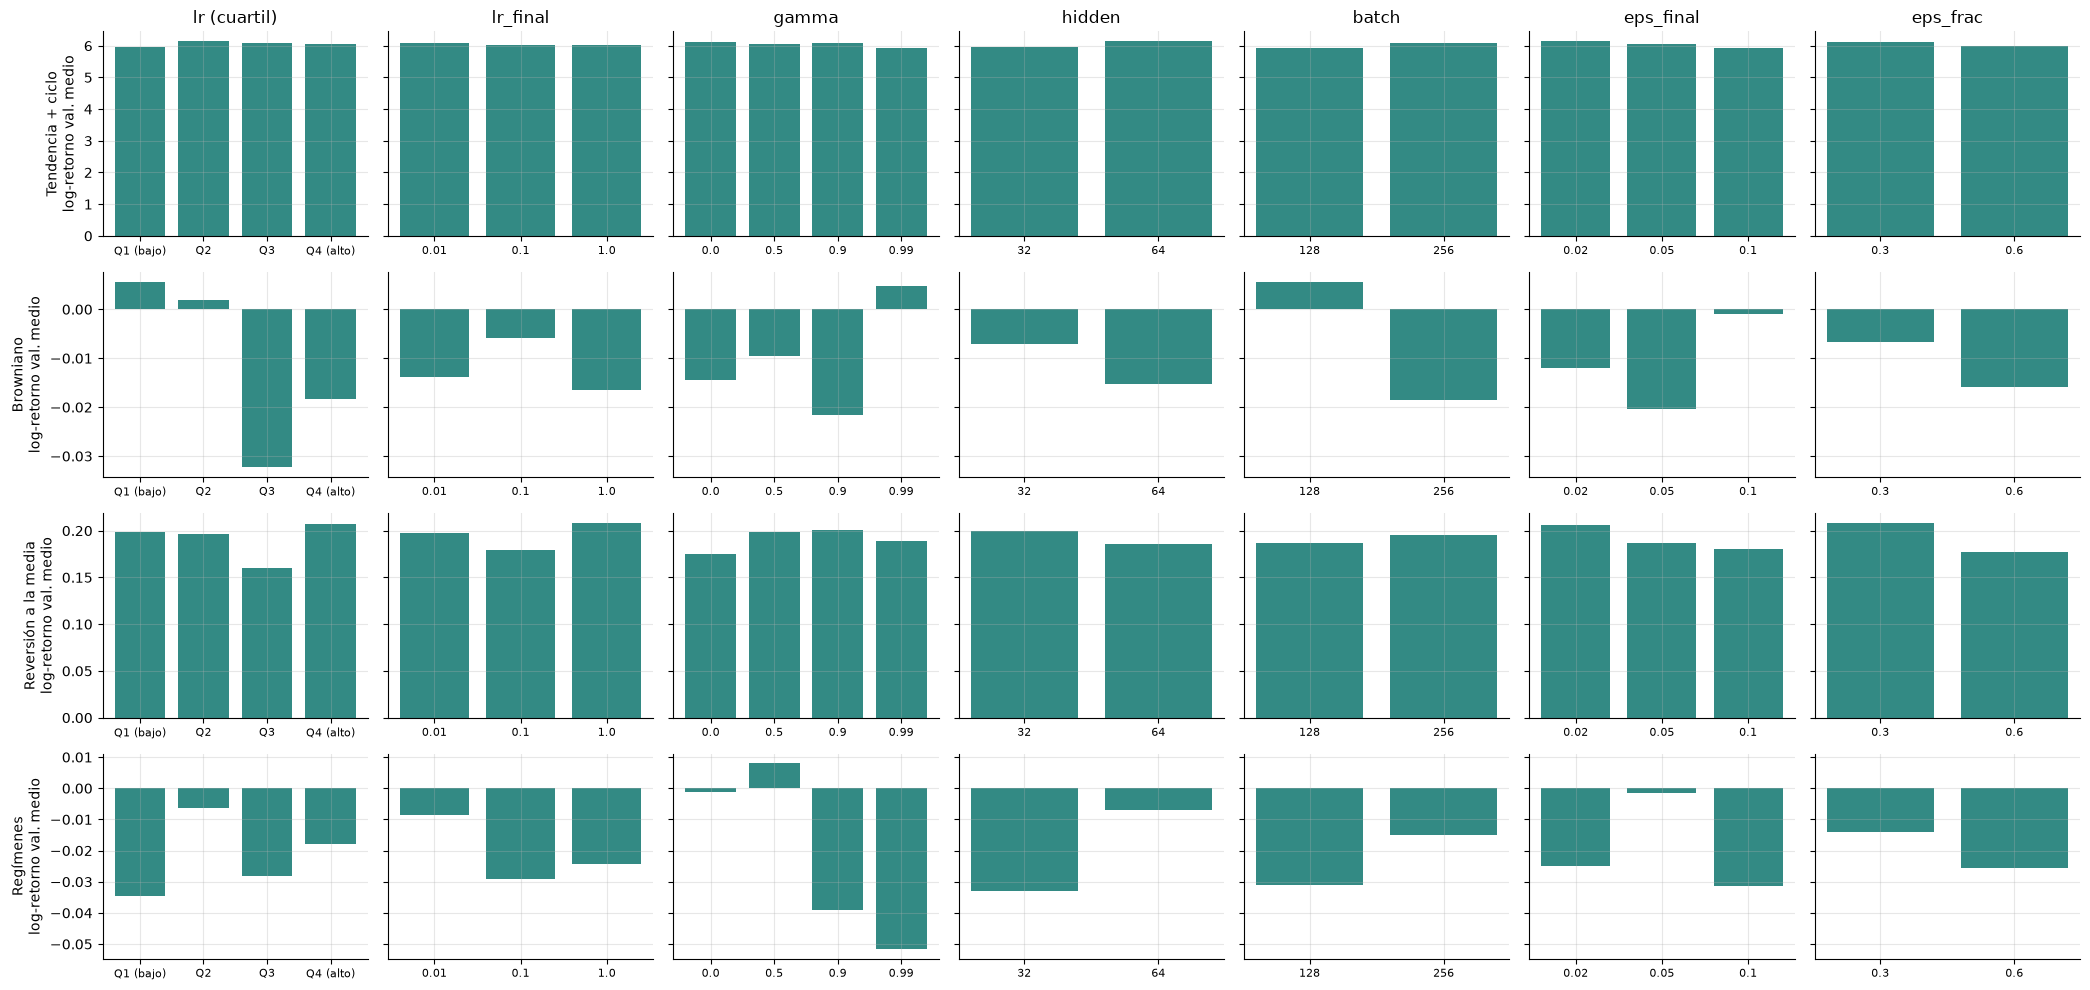

In [11]:
b = busqueda.copy()
b["lr (cuartil)"] = pd.qcut(b.lr.rank(method="first"), 4, labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])
columnas = ["lr (cuartil)", "lr_final", "gamma", "hidden", "batch", "eps_final", "eps_frac"]
fig, axs = plt.subplots(len(GENS), len(columnas), figsize=(21, 10), sharey="row")
for i, g in enumerate(GENS):
    for j, col in enumerate(columnas):
        m = b[b.gen == g].groupby(col, observed=True).score.mean()
        axs[i, j].bar(range(len(m)), m.values, color="#0f766e", alpha=0.85)
        axs[i, j].set_xticks(range(len(m)))
        axs[i, j].set_xticklabels([str(x) for x in m.index], fontsize=8)
        if i == 0:
            axs[i, j].set_title(col)
        if j == 0:
            axs[i, j].set_ylabel(f"{g}\nlog-retorno val. medio")
plt.tight_layout()
plt.savefig(FIGS / "sensibilidad_busqueda.png", bbox_inches="tight")
plt.show()

**Qué se ve en la búsqueda**

- ***Tendencia + ciclo*** es casi insensible al ajuste: cada entrenamiento saca entre 5,4 y 6,2 en validación y casi ningún hiperparámetro mueve el resultado más de ~0,2. La señal es tan clara que casi cualquier red la aprende. Lo poco que se nota: un $\epsilon$ final alto (0,1) y $\gamma = 0{,}99$ la empeoran algo (5,93 y 5,92 frente a 6,1).
- ***Reversión a la media*** es donde más pesa el ajuste (de 0,09 a 0,28 entre entrenamientos). $\gamma = 0$ es peor (0,175) que $\gamma$ entre 0,5 y 0,99 (0,19–0,20): con un horizonte de un solo paso, la ganancia esperada del paso siguiente apenas compensa la comisión de entrada. Es el mismo hallazgo que con Q-Learning en la práctica 1.
- ***Regímenes***: un $\gamma$ alto perjudica claramente (−0,039 con 0,9 y −0,052 con 0,99, frente a +0,008 con 0,5). Con una señal casi inexistente, un descuento alto hace que la red se apoye en estimaciones del futuro muy ruidosas y opere de más. El 15 % de los entrenamientos acaba sin operar.
- ***Browniano***: el 55 % de los entrenamientos acaba sin operar y el resto pierde un poco. Las diferencias entre configuraciones (de −0,09 a +0,02) son ruido, así que el ajuste de este mercado es un desempate, igual que en la práctica 1.
- **La tasa de aprendizaje decreciente** gana en la reevaluación en los cuatro mercados (las cuatro configuraciones elegidas terminan con `lr·0,1` o `lr·0,01`), coherente con lo que ya vimos en SARSA: con una recompensa que es casi todo ruido, hay que terminar el entrenamiento con pasos pequeños.

### 6.2 Reevaluación de las mejores configuraciones

Las `TOP_K` mejores de cada mercado se reentrenan con el número de episodios del entrenamiento final y semillas nuevas. Se queda la de mayor puntuación media.

In [12]:
f_reeval, f_params = CACHE / "reevaluacion.csv", CACHE / "mejores_params.json"
if RECOMPUTE or not f_reeval.exists():
    ranking = busqueda.groupby(["gen", "config"]).score.mean().reset_index()
    top = ranking.sort_values(["gen", "score"], ascending=[True, False]).groupby("gen").head(TOP_K)
    meta = [(r.gen, int(r.config), s) for r in top.itertuples() for s in SEMILLAS_REEVAL]
    salidas = ejecutar([dict(gen=g, params=params_de(configs[c]), n_ep=N_EP_FINAL, semilla=s, eval_cada=EVAL_CADA) for g, c, s in meta], "reevaluación")
    curvas = {}
    filas = []
    for (g, c, s), o in zip(meta, salidas):
        filas.append({"gen": g, "config": c, "semilla": s, "score": puntuacion(o["hist"])})
        curvas.setdefault((g, c), []).append(o["hist"])
    reeval = pd.DataFrame(filas).groupby(["gen", "config"]).score.mean().reset_index()
    reeval = reeval.merge(pd.DataFrame(configs), left_on="config", right_on="id").drop(columns="id")
    reeval.to_csv(f_reeval, index=False)
    dump({k: {"ep": v[0]["ep"], "val": np.mean([h["val"] for h in v], 0)} for k, v in curvas.items()}, CACHE / "curvas_reeval.joblib")
    elegida = reeval.sort_values("score", ascending=False, kind="stable").groupby("gen").head(1)
    MEJORES_PARAMS = {r.gen: {k: (int(getattr(r, k)) if k in ("hidden", "batch") else float(getattr(r, k))) for k in CLAVES} for r in elegida.itertuples()}
    json.dump(MEJORES_PARAMS, open(f_params, "w", encoding="utf-8"), indent=1, ensure_ascii=False)
else:
    reeval = pd.read_csv(f_reeval)
    MEJORES_PARAMS = json.load(open(f_params, encoding="utf-8"))
display(reeval.sort_values(["gen", "score"], ascending=[True, False]).reset_index(drop=True).round(4))

,gen,config,score,lr,lr_final,gamma,hidden,batch,eps_final,eps_frac
0,Browniano,5,0.0100,0.0001,0.01,0.00,32,256,0.05,0.3
1,Browniano,8,0.0000,0.0001,0.10,0.99,32,128,0.10,0.6
2,Regímenes,4,0.0499,0.0004,0.01,0.50,64,128,0.10,0.6
3,Regímenes,5,-0.0041,0.0001,0.01,0.00,32,256,0.05,0.3
4,Reversión a la media,3,0.1987,0.0015,0.01,0.90,64,256,0.02,0.6
5,Reversión a la media,5,0.0609,0.0001,0.01,0.00,32,256,0.05,0.3
6,Tendencia + ciclo,6,6.0729,0.0006,0.10,0.50,64,256,0.02,0.3
7,Tendencia + ciclo,1,6.0666,0.0016,0.10,0.99,64,256,0.02,0.3


### 6.3 Curvas de reevaluación y número de episodios

Curvas de validación de las `TOP_K` mejores configuraciones de cada mercado (media de 2 semillas). Sirven para decidir cuántos episodios hacen falta: el entrenamiento final usa `N_EP_FINAL` episodios, que es el punto hasta el que se han visto estabilizarse las curvas.

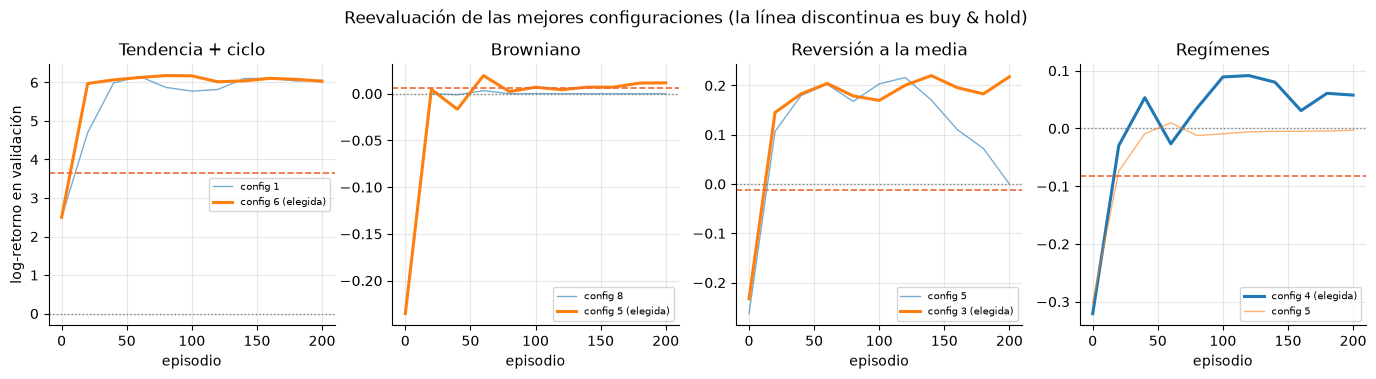

In [13]:
curvas = load(CACHE / "curvas_reeval.joblib")
fig, axs = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, g in zip(axs, GENS):
    for (gg, c), v in curvas.items():
        if gg == g:
            elegido = MEJORES_PARAMS[g]["lr"] == configs[c]["lr"]
            ax.plot(v["ep"], v["val"], lw=2.2 if elegido else 1, alpha=1 if elegido else 0.6, label=f"config {c}" + (" (elegida)" if elegido else ""))
    ax.axhline(evaluate(val_series(g), BASELINES["Buy & Hold"])["log_ret"].mean(), color="#ed6a37", ls="--", lw=1.2)
    ax.axhline(0, color="gray", ls=":", lw=1)
    ax.set_title(g)
    ax.set_xlabel("episodio")
    ax.legend(fontsize=7)
axs[0].set_ylabel("log-retorno en validación")
fig.suptitle("Reevaluación de las mejores configuraciones (la línea discontinua es buy & hold)", y=1.04)
plt.savefig(FIGS / "curvas_reevaluacion.png", bbox_inches="tight")
plt.show()

**Número de episodios.** Con 200 episodios las curvas de las configuraciones elegidas ya se han estabilizado: *tendencia + ciclo* en unos 40–60 episodios, *reversión a la media* oscila entre 0,17 y 0,22 desde el episodio 40, y *regímenes* y *browniano* se mueven alrededor de un valor casi constante. Se fija `N_EP_FINAL = 200`; para tener una referencia, los algoritmos tabulares de la práctica 1 necesitaron 3000.

La gráfica enseña además por qué se promedian las tres últimas evaluaciones y se reevalúa con semillas nuevas: en *reversión a la media* la segunda mejor configuración (`lr` pequeño y $\gamma = 0$) llegaba a 0,2 en validación hacia el episodio 120, pero **acaba «apagándose»** y cae a 0: la política deja de comprar. Es la inestabilidad que se esperaba (hipótesis 2).

### 6.4 Periodo de copia de la red objetivo ($k$) para el Doble DQN

La red objetivo $Q'$ se refresca copiando $Q$ cada $k$ pasos. Con $k$ pequeño $Q'$ casi no se distingue de $Q$ (y se pierde la estabilidad); con $k$ grande el objetivo queda desfasado. Se prueban 250, 1000 y 4000 pasos (un episodio son 494 pasos), con los demás hiperparámetros ya fijados y semillas nuevas.

In [14]:
KS = (250, 1000, 4000)
SEMILLAS_K = tuple(s + 10 for s in SEMILLAS_REEVAL)
f_k = CACHE / "periodo_copia.csv"
if RECOMPUTE or not f_k.exists():
    meta = [(g, k, s) for g in GENS for k in KS for s in SEMILLAS_K]
    salidas = ejecutar([dict(gen=g, params={**MEJORES_PARAMS[g], "target_every": k}, n_ep=N_EP_FINAL, semilla=s, eval_cada=EVAL_CADA, variante="Doble DQN")
                        for g, k, s in meta], "periodo de copia")
    tabla_k = pd.DataFrame([{"gen": g, "k": k, "semilla": s, "score": puntuacion(o["hist"])} for (g, k, s), o in zip(meta, salidas)])
    tabla_k.to_csv(f_k, index=False)
else:
    tabla_k = pd.read_csv(f_k)
pk = tabla_k.groupby(["gen", "k"]).score.mean().unstack()
display(pk.round(4))
for g in GENS:
    MEJORES_PARAMS[g]["target_every"] = int(pk.loc[g].idxmax())
json.dump(MEJORES_PARAMS, open(f_params, "w", encoding="utf-8"), indent=1, ensure_ascii=False)

print("\nHiperparámetros elegidos:")
display(pd.DataFrame(MEJORES_PARAMS).T[list(CLAVES) + ["target_every"]].astype({"hidden": int, "batch": int, "target_every": int}))

k,250,1000,4000
gen,,,
Browniano,0.0015,0.0015,0.0015
Regímenes,0.0014,0.0209,0.0000
Reversión a la media,0.2229,0.2071,0.1937
Tendencia + ciclo,6.1205,6.1662,6.1000



Hiperparámetros elegidos:


,lr,lr_final,gamma,hidden,batch,eps_final,eps_frac,target_every
Tendencia + ciclo,0.000625,0.10,0.5,64,256,0.02,0.3,1000
Reversión a la media,0.001477,0.01,0.9,64,256,0.02,0.6,250
Regímenes,0.000367,0.01,0.5,64,128,0.10,0.6,1000
Browniano,0.000121,0.01,0.0,32,256,0.05,0.3,250


**Hiperparámetros elegidos y qué significan**

| Mercado | `lr` → final | $\gamma$ | neuronas | lote | $\epsilon$ final (en la fracción de episodios) | $k$ |
|---|---|---|---|---|---|---|
| Tendencia + ciclo | $6{,}3\cdot10^{-4}$ → ÷10 | 0,5 | 64 | 256 | 0,02 (30 %) | 1000 |
| Browniano | $1{,}2\cdot10^{-4}$ → ÷100 | 0 | 32 | 256 | 0,05 (30 %) | (irrelevante) |
| Reversión a la media | $1{,}5\cdot10^{-3}$ → ÷100 | 0,9 | 64 | 256 | 0,02 (60 %) | 250 |
| Regímenes | $3{,}7\cdot10^{-4}$ → ÷100 | 0,5 | 64 | 128 | 0,10 (60 %) | 1000 |

- **El periodo de copia $k$ no es decisivo.** Las diferencias (por ejemplo 0,223 con $k=250$ frente a 0,194 con $k=4000$ en *reversión*) son del tamaño de la variación entre semillas. En *reversión a la media* conviene copiar más a menudo; con $k$ grande el objetivo queda desfasado respecto a lo que la red ya ha aprendido.
- **En el browniano $\gamma = 0$ y el periodo de copia da igual** (0,0015 con los tres valores): con $\gamma = 0$ el objetivo es solo $r_t$, no hay estado siguiente, y por tanto no hay red objetivo ni estimador doble que valgan. Es una comprobación útil de la implementación: en ese mercado **DQN y Doble DQN dan exactamente los mismos números** (sección 7).
- Todos los mercados prefieren $\gamma$ bajo o medio (0–0,9). Es lo mismo que le pasó a Monte Carlo en la práctica 1: el retorno futuro es muy ruidoso y apoyarse en él (incluso con una red) cuesta más de lo que aporta.

## 7. Entrenamiento final, curvas de aprendizaje y resultados en test

Con los hiperparámetros elegidos en cada mercado se entrenan **las cuatro variantes principales** (DQN, Doble DQN, DQN en duelo y Doble DQN en duelo) con **5 semillas independientes** y `N_EP_FINAL` episodios cada una, y con los mismos hiperparámetros en todas, para que la diferencia entre variantes sea de la variante. La política *greedy* se evalúa en validación cada `EVAL_CADA` episodios.

In [15]:
VARIANTES_PRINCIPALES = ["DQN", "Doble DQN", "DQN en duelo", "Doble DQN en duelo"]
COLORES = {"DQN": "#0f766e", "DQN + red objetivo": "#5eead4", "Doble DQN": "#be185d", "DQN en duelo": "#a16207", "Doble DQN en duelo": "#4d7c0f",
           "Buy & Hold": "#ed6a37", "Aleatorio": "#16a34a", "Q-Learning": "#2a78d6", "SARSA": "#7c3aed", "Monte Carlo": "#c2410c"}
ENVS = {"SimpleTradingEnv": SimpleTradingEnv, "ExtendedTradingEnv": ExtendedTradingEnv}

f_final = CACHE / "runs_final.joblib"
if RECOMPUTE or not f_final.exists():
    RUNS = ejecutar([dict(gen=g, params=MEJORES_PARAMS[g], n_ep=N_EP_FINAL, semilla=s, eval_cada=EVAL_CADA, variante=v)
                     for v in VARIANTES_PRINCIPALES for g in GENS for s in SEMILLAS_FINAL], "entrenamiento final")
    dump(RUNS, f_final)
else:
    RUNS = load(f_final)
runs_de = lambda v, g, runs=None: [r for r in (runs or RUNS) if r["variante"] == v and r["gen"] == g]
print(f"{len(RUNS)} entrenamientos finales ({len(VARIANTES_PRINCIPALES)} variantes × {len(GENS)} mercados × {len(SEMILLAS_FINAL)} semillas)")

80 entrenamientos finales (4 variantes × 4 mercados × 5 semillas)


**Coste por episodio.** Los tiempos de los entrenamientos paralelos no se pueden comparar (compiten por la CPU). Como en la práctica 1, se mide aparte, en serie y sin validar, cuánto tarda un episodio de cada variante con los hiperparámetros de cada mercado (se descartan los primeros episodios, que solo llenan la memoria y no actualizan la red). El tiempo hasta convergencia es ese coste por el nº de episodios que tarda en converger.

In [16]:
def coste_episodio(variante, gen, params, n_ep=16, env_cls=SimpleTradingEnv):
    _, h = entrenar(gen, {**params, **VARIANTES[variante]}, n_ep, 900, None, 1, calibrar(gen, env_cls), env_cls)
    return 1000 * float(np.median(h["t_ep"][6:]))                 # ms por episodio


f_coste = CACHE / "coste_ms.csv"
if RECOMPUTE or not f_coste.exists():
    coste = pd.DataFrame([{"variante": v, "gen": g, "ms": coste_episodio(v, g, MEJORES_PARAMS[g])} for v in VARIANTES_PRINCIPALES for g in GENS])
    coste.to_csv(f_coste, index=False)
else:
    coste = pd.read_csv(f_coste)
COSTE = {(r.variante, r.gen): r.ms for r in coste.itertuples()}
display(coste.pivot(index="gen", columns="variante", values="ms").round(0).rename_axis("ms por episodio"))

variante,DQN,DQN en duelo,Doble DQN,Doble DQN en duelo
ms por episodio,,,,
Browniano,134.0,165.0,138.0,183.0
Regímenes,135.0,164.0,147.0,180.0
Reversión a la media,146.0,180.0,161.0,198.0
Tendencia + ciclo,151.0,191.0,153.0,204.0


### Curvas de aprendizaje

Log-retorno medio de la política *greedy* en validación (media de las 5 semillas y rango). Las líneas verticales punteadas marcan el episodio de convergencia de cada variante (mediana de las semillas).

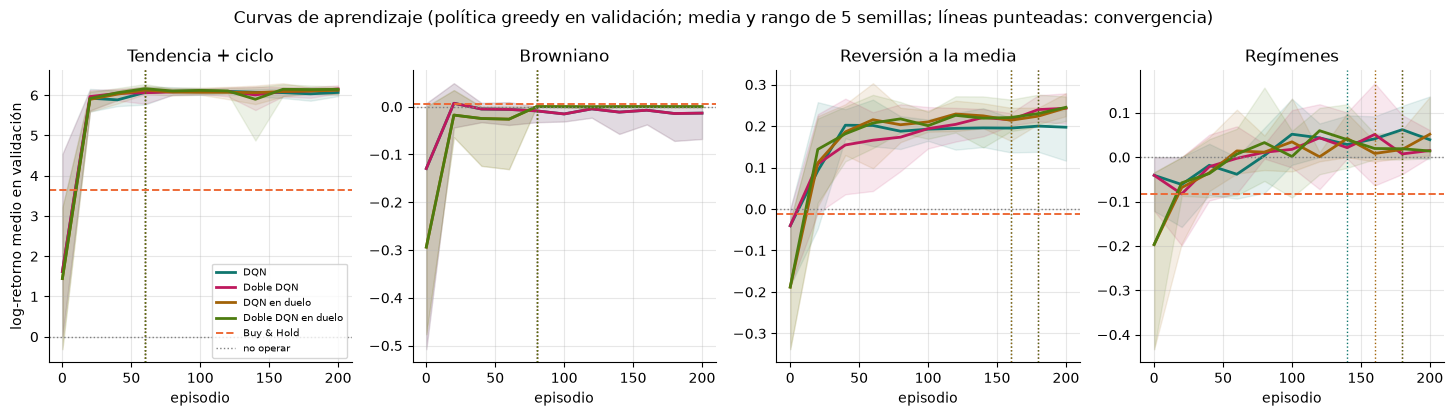

In [17]:
def conv_de(runs):
    return float(np.median([convergence_episode(r["hist"]["ep"], r["hist"]["val"]) for r in runs]))


fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, g in zip(axs, GENS):
    for v in VARIANTES_PRINCIPALES:
        rs = runs_de(v, g)
        val = np.array([r["hist"]["val"] for r in rs])
        ep = rs[0]["hist"]["ep"]
        ax.plot(ep, val.mean(0), color=COLORES[v], lw=2, label=v)
        ax.fill_between(ep, val.min(0), val.max(0), color=COLORES[v], alpha=0.10)
        ax.axvline(conv_de(rs), color=COLORES[v], ls=":", lw=1)
    ax.axhline(evaluate(val_series(g), BASELINES["Buy & Hold"])["log_ret"].mean(), color=COLORES["Buy & Hold"], ls="--", lw=1.4, label="Buy & Hold")
    ax.axhline(0, color="gray", ls=":", lw=1, label="no operar")
    ax.set_title(g)
    ax.set_xlabel("episodio")
axs[0].set_ylabel("log-retorno medio en validación")
axs[0].legend(fontsize=7, loc="lower right")
fig.suptitle("Curvas de aprendizaje (política greedy en validación; media y rango de 5 semillas; líneas punteadas: convergencia)", y=1.04)
plt.savefig(FIGS / "curvas_aprendizaje.png", bbox_inches="tight")
plt.show()

**Lectura de las curvas**

- ***Tendencia + ciclo***: las cuatro variantes pasan de 1,5 a casi 6 en los primeros 20 episodios y **convergen en 60** (los tabulares, en 300–500). La red generaliza entre tendencias parecidas, y no tiene que visitar cada intervalo como una tabla.
- ***Browniano***: las variantes en duelo empiezan peor (−0,3 antes de entrenar) pero todas acaban en torno a 0 hacia el episodio 20–80: aprenden a no operar.
- ***Reversión a la media***: sube a ~0,2 en unos 40 episodios y luego mejora despacio. Converge hacia los 160–180 episodios (frente a 1600–2200 de los tabulares) con una banda entre semillas bastante ancha.
- ***Regímenes***: la curva es ruidosa, con una banda de ±0,1 entre semillas y una media cercana a 0 o ligeramente positiva. Es el mercado donde el resultado de una sola semilla significa muy poco.

### Evaluación en test y tabla comparativa

Cada agente entrenado se evalúa, sin explorar, en las **100 series de test** del mercado (las mismas que en la práctica 1). Las cifras de cada variante son la media de 5 semillas × 100 series; la desviación entre semillas mide cuánto cambia el log-retorno medio de una semilla a otra.

In [18]:
def evaluar_run(run):
    """Evalúa un agente entrenado en las series de test de su mercado (las genera el propio proceso)."""
    torch.set_num_threads(1)
    test = [make_series(run["gen"], SEED_TEST + i) for i in range(N_TEST)]
    pol = politica_desde(run["pol"])
    return evaluate(test, lambda i, p=pol: p, ENVS[run["env"]])


def evaluar_todos(runs):
    return Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(evaluar_run)(r) for r in runs)


def fila(res_list, nombre, g, runs=None, ms=None):
    res = pd.concat(res_list, ignore_index=True)
    bh = res_base[(g, "Buy & Hold")]["log_ret"].values
    extra = {"% series > B&H": 100 * np.mean(res["log_ret"].values > np.tile(bh, len(res) // len(bh)))}
    if runs is not None:
        convs = [convergence_episode(r["hist"]["ep"], r["hist"]["val"]) for r in runs]
        extra.update({"Std log-ret. entre semillas": float(np.std([d["log_ret"].mean() for d in res_list])),
                      "Episodios hasta convergencia": float(np.median(convs)), "ms/episodio": ms,
                      "Tiempo hasta convergencia (s)": float(np.median(convs)) * ms / 1000})
    return summarize(res, nombre, g, extra)


t0 = time.perf_counter()
EVAL_RUNS = evaluar_todos(RUNS)
print(f"{len(RUNS)} evaluaciones en test en {time.perf_counter() - t0:.0f} s")

filas = [{**summarize(res_base[(g, n)], n, g), "% series > B&H": 100 * np.mean(res_base[(g, n)]["log_ret"].values > res_base[(g, "Buy & Hold")]["log_ret"].values)}
         for g in GENS for n in BASELINES]
for g in GENS:
    for v in VARIANTES_PRINCIPALES:
        idx = [i for i, r in enumerate(RUNS) if r["variante"] == v and r["gen"] == g]
        filas.append(fila([EVAL_RUNS[i] for i in idx], v, g, [RUNS[i] for i in idx], COSTE[(v, g)]))
tabla = pd.DataFrame(filas).set_index(["Generador", "Agente"])
tabla.to_csv("resultados_dqn.csv")

FMT = {"Log-ret. medio": "{:.3f}", "Ret. geométrico (%)": "{:,.1f}", "Ret. mediano (%)": "{:,.1f}", "% series > B&H": "{:.0f}", "Sharpe": "{:.2f}", "Max DD (%)": "{:.1f}",
       "Operaciones": "{:.1f}", "% tiempo invertido": "{:.1f}", "Std log-ret. entre semillas": "{:.3f}", "Episodios hasta convergencia": "{:.0f}",
       "ms/episodio": "{:.0f}", "Tiempo hasta convergencia (s)": "{:.1f}"}
COLS = ["Log-ret. medio", "Ret. geométrico (%)", "% series > B&H", "Sharpe", "Max DD (%)", "Operaciones", "Std log-ret. entre semillas",
        "Episodios hasta convergencia", "ms/episodio", "Tiempo hasta convergencia (s)"]
ORDEN = VARIANTES_PRINCIPALES + ["Buy & Hold", "Aleatorio"]
principal = tabla.loc[[(g, a) for g in GENS for a in ORDEN], COLS]
display(principal.style.format(FMT, na_rep="—"))

80 evaluaciones en test en 25 s


### Comparación con los algoritmos tabulares de la práctica 1

Mismas series de test y mismas métricas (`../tabla_comparativa.csv`). Hay que tener en cuenta que los algoritmos tabulares se entrenaron 3000 episodios y DQN solo `N_EP_FINAL`: la red generaliza entre estados parecidos y aprende en muchos menos episodios, pero **cada episodio le cuesta mucho más** (una actualización de la red por cada 4 pasos, frente a una suma en una tabla).

Log-retorno medio en test (entre paréntesis, desviación entre semillas):


,Q-Learning,SARSA,Monte Carlo,DQN,Doble DQN,DQN en duelo,Doble DQN en duelo,Buy & Hold,Aleatorio
Tendencia + ciclo,+6.338 (±0.102),+6.316 (±0.234),+6.522 (±0.039),+6.092 (±0.182),+6.241 (±0.101),+6.193 (±0.066),+6.260 (±0.100),+3.316,+1.558
Browniano,+0.000 (±0.000),+0.000 (±0.000),-0.012 (±0.025),-0.005 (±0.010),-0.005 (±0.010),-0.000 (±0.001),-0.000 (±0.001),-0.062,-0.187
Reversión a la media,+0.155 (±0.042),+0.203 (±0.025),+0.238 (±0.015),+0.175 (±0.045),+0.201 (±0.020),+0.189 (±0.030),+0.197 (±0.029),-0.005,-0.169
Regímenes,+0.040 (±0.022),+0.000 (±0.000),+0.031 (±0.011),+0.030 (±0.040),+0.008 (±0.011),+0.026 (±0.016),+0.014 (±0.019),-0.128,-0.220


Convergencia (episodios / segundos):


,Q-Learning,SARSA,Monte Carlo,DQN,Doble DQN,DQN en duelo,Doble DQN en duelo
Tendencia + ciclo,300 ep. / 2.4 s,500 ep. / 4.0 s,500 ep. / 4.8 s,60 ep. / 9.1 s,60 ep. / 9.2 s,60 ep. / 11.4 s,60 ep. / 12.2 s
Browniano,400 ep. / 4.2 s,1700 ep. / 13.0 s,700 ep. / 6.5 s,80 ep. / 10.7 s,80 ep. / 11.0 s,80 ep. / 13.2 s,80 ep. / 14.7 s
Reversión a la media,2200 ep. / 18.6 s,1600 ep. / 14.1 s,1600 ep. / 17.3 s,160 ep. / 23.3 s,180 ep. / 29.0 s,160 ep. / 28.8 s,180 ep. / 35.7 s
Regímenes,2000 ep. / 16.6 s,600 ep. / 5.5 s,1300 ep. / 11.5 s,140 ep. / 18.8 s,180 ep. / 26.4 s,160 ep. / 26.3 s,180 ep. / 32.4 s


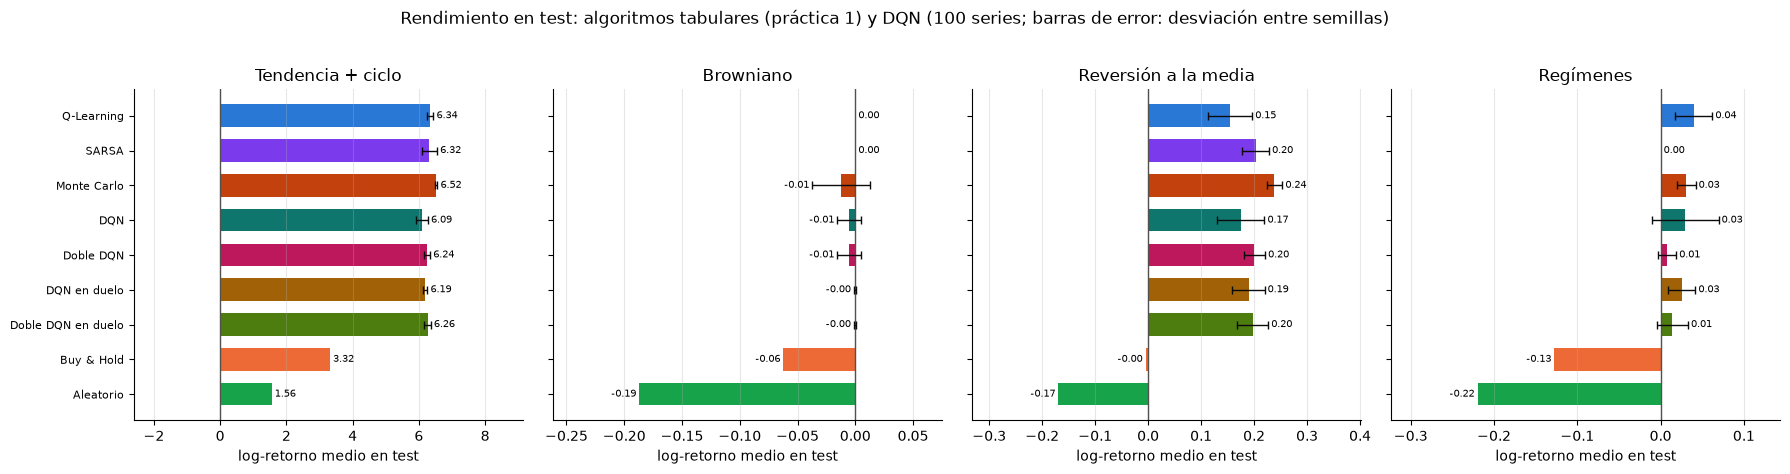

In [19]:
TABULARES = ["Q-Learning", "SARSA", "Monte Carlo"]
cmp_ = pd.concat([prac1.loc[[(g, a) for g in GENS for a in TABULARES + ["Buy & Hold", "Aleatorio"]], COLS], principal.loc[[(g, a) for g in GENS for a in VARIANTES_PRINCIPALES], COLS]])
ALGOS = TABULARES + VARIANTES_PRINCIPALES
resumen = pd.DataFrame({a: [f"{cmp_.loc[(g, a), 'Log-ret. medio']:+.3f} (±{cmp_.loc[(g, a), 'Std log-ret. entre semillas']:.3f})" for g in GENS] for a in ALGOS}, index=GENS)
resumen["Buy & Hold"] = [f"{cmp_.loc[(g, 'Buy & Hold'), 'Log-ret. medio']:+.3f}" for g in GENS]
resumen["Aleatorio"] = [f"{cmp_.loc[(g, 'Aleatorio'), 'Log-ret. medio']:+.3f}" for g in GENS]
print("Log-retorno medio en test (entre paréntesis, desviación entre semillas):")
display(resumen)
conv = pd.DataFrame({a: [f"{cmp_.loc[(g, a), 'Episodios hasta convergencia']:.0f} ep. / {cmp_.loc[(g, a), 'Tiempo hasta convergencia (s)']:.1f} s" for g in GENS] for a in ALGOS}, index=GENS)
print("Convergencia (episodios / segundos):")
display(conv)

fig, axs = plt.subplots(1, 4, figsize=(18, 4.6))
mostrar = ALGOS + ["Buy & Hold", "Aleatorio"]
for ax, g in zip(axs, GENS):
    vals = [cmp_.loc[(g, a), "Log-ret. medio"] for a in mostrar]
    errs = [cmp_.loc[(g, a), "Std log-ret. entre semillas"] if a in ALGOS else 0 for a in mostrar]
    ax.barh(range(len(mostrar)), vals, color=[COLORES[a] for a in mostrar], height=0.65)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(range(len(mostrar)), mostrar if g == GENS[0] else [""] * len(mostrar), fontsize=8)
    ax.invert_yaxis()
    ax.set_title(g)
    ax.set_xlabel("log-retorno medio en test")
    for k, (v, e) in enumerate(zip(vals, errs)):
        if e > 0:
            ax.errorbar(v, k, xerr=e, fmt="none", ecolor="#0b0b0b", capsize=3, lw=1)
        ax.text(v + e if v >= 0 else v - e, k, f" {v:.2f} ", va="center", ha="left" if v >= 0 else "right", fontsize=7)
    lo, hi = min(0, min(vals)), max(0, max(vals))
    pad = 0.4 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)
    ax.grid(axis="y", visible=False)
fig.suptitle("Rendimiento en test: algoritmos tabulares (práctica 1) y DQN (100 series; barras de error: desviación entre semillas)", y=1.02)
plt.tight_layout()
plt.savefig(FIGS / "comparativa_practica1.png", bbox_inches="tight")
plt.show()

### Análisis de los resultados en test

**Frente a las referencias.** Todas las variantes ganan a *buy & hold* y al agente aleatorio en los cuatro mercados (en el browniano, quedándose casi siempre fuera), y aprenden la estrategia esperada de cada mercado (sección 8.1).

- **Tendencia + ciclo:** log-retorno de 6,09 a 6,26, frente a 3,32 de *buy & hold* y 6,11 de la regla de *momentum*. Ganan a *buy & hold* en el 98 % de las series con unas 48–54 operaciones por episodio (la regla opera 93). Es el mismo *momentum* con histéresis de la práctica 1, pero **algo por debajo de los tabulares** (6,32–6,52), con una diferencia pequeña (0,1–0,4) frente al valor total.
- **Browniano:** −0,005 con DQN y Doble DQN (0,7 operaciones por episodio) y −0,000 con las variantes en duelo (0,06). Es prácticamente «no operar» y mejora a *buy & hold* (−0,062); empata con Q-Learning y SARSA (0) y mejora a Monte Carlo (−0,012).
- **Reversión a la media:** de 0,175 (DQN) a 0,201 (Doble DQN), es decir, +19 % y +22 % geométrico, frente al −0,5 % de *buy & hold* y el +7 % de la regla *contrarian*. Doble DQN (0,201) iguala a SARSA (0,203), supera a Q-Learning (0,155) y queda por debajo de Monte Carlo (0,238). Gana a *buy & hold* en el 83–87 % de las series.
- **Regímenes:** DQN saca 0,030 (+3 %), igual que Monte Carlo (0,031) y algo por debajo de Q-Learning (0,040). Doble DQN, 0,008. Aquí la variación entre semillas (0,011–0,040) es del tamaño de las diferencias entre variantes, así que **no se puede decir que una sea mejor**.

**Entre variantes.**

- **Doble DQN reduce la variación entre semillas** en los tres mercados con señal: de 0,182 a 0,101 en *tendencia + ciclo*, de 0,045 a 0,020 en *reversión* y de 0,040 a 0,011 en *regímenes*. Es el «aprendizaje más estable» de las diapositivas. La media, en cambio, apenas cambia, y con solo 5 semillas las diferencias de media entre variantes son pequeñas frente a esa dispersión.
- **El DQN en duelo no aporta una mejora clara**, como se esperaba: con 3 acciones y solo 2 con efecto en cada estado, separar $V(s)$ de $A(s,a)$ da poco. Tiene un coste: un 22–26 % más de tiempo por episodio. Su único efecto visible es que en el browniano casi no opera (0,06 operaciones frente a 0,69).

**Convergencia y coste.**

- DQN converge en **muchos menos episodios** que los algoritmos tabulares: 60 frente a 300–500 en *tendencia + ciclo*; 160–180 frente a 1600–2200 en *reversión*; 140–180 frente a 600–2000 en *regímenes*.
- Pero **cada episodio cuesta entre 12 y 25 veces más** (134–204 ms frente a 8–11 ms: una actualización de red por cada 4 pasos, frente a una suma en una tabla). El tiempo hasta converger en segundos es por eso **peor**: 9 s frente a 2,4–4,8 s en *tendencia + ciclo* y 23–36 s frente a 14–19 s en *reversión*. DQN gasta menos datos (episodios), pero más cómputo.
- **Doble DQN** añade un 1–10 % al coste de un episodio (hay que mantener y copiar una segunda red) y **el duelo** un 22–26 %.

**Comparación con la práctica 1.** En este problema DQN **no supera** a los algoritmos tabulares: empata con ellos en los mercados difíciles y queda ligeramente por debajo en *tendencia + ciclo*. No es sorprendente: el estado tiene solo dos variables, y una tabla de 10–20 intervalos ya representa casi cualquier función de la tendencia. La ventaja de una red (generalizar y admitir entradas continuas o de más dimensiones) no se aprovecha con un estado tan pequeño. Eso es lo que se prueba en la sección 8.3.

## 8. Análisis

### 8.1 Política aprendida: ¿es la estrategia esperada?

Para cada nivel de tendencia y según la posición actual, se muestra la fracción de las 5 semillas que **quedan invertidas tras actuar**: estando fuera, eso significa comprar; estando dentro, no vender (verde oscuro = las 5 semillas; blanco = ninguna). Es la misma figura que en la práctica 1: el hueco entre las filas «fuera» y «dentro» es la **histéresis**, que evita pagar comisión por cambios de posición pequeños.

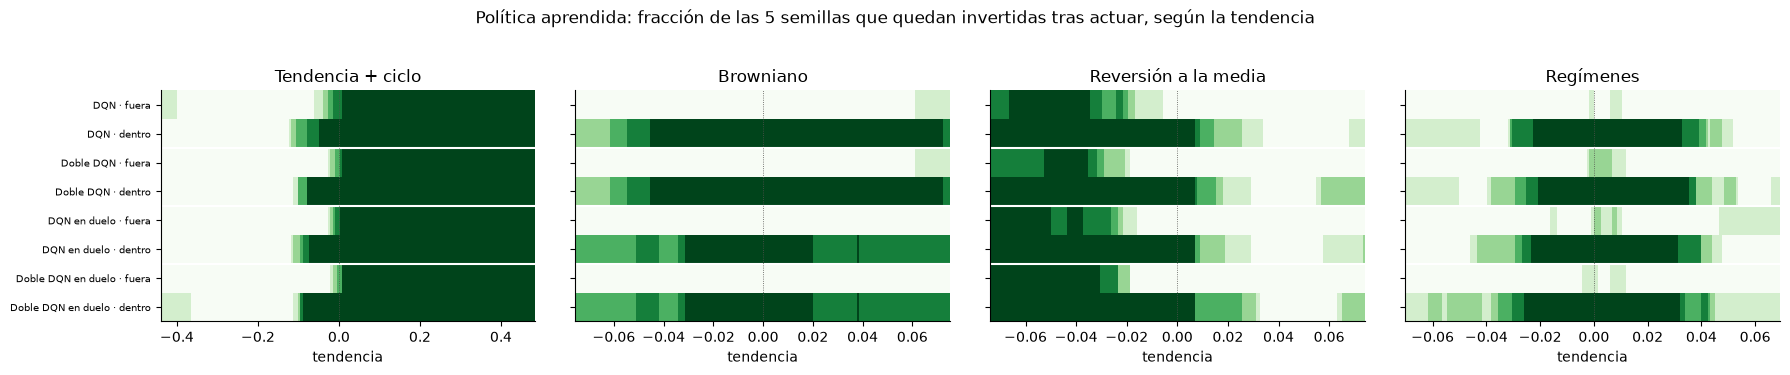

In [20]:
def mapa_politica(runs, g):
    mu, sd = ESCALAS[g][0][0], ESCALAS[g][1][0]
    xs = np.linspace(mu - 3 * sd, mu + 3 * sd, 161)
    pols = [politica_desde(r["pol"]) for r in runs]
    M = []
    for pos in (0, 1):
        acts = np.array([[p(np.array([t, pos], dtype=np.float32)) for t in xs] for p in pols])
        M.append(((acts == 2) if pos == 0 else (acts != 0)).mean(0))
    return xs, np.array(M)


fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, g in zip(axs, GENS):
    filas_m, etiquetas = [], []
    for v in VARIANTES_PRINCIPALES:
        xs, M = mapa_politica(runs_de(v, g), g)
        filas_m += list(M)
        etiquetas += [f"{v} · fuera", f"{v} · dentro"]
    ax.pcolormesh(np.append(xs - (xs[1] - xs[0]) / 2, xs[-1] + (xs[1] - xs[0]) / 2), np.arange(len(filas_m) + 1), np.array(filas_m), cmap="Greens", vmin=0, vmax=1, shading="flat")
    for k in range(2, len(filas_m), 2):
        ax.axhline(k, color="white", lw=1.5)
    ax.axvline(0, color="#52514e", lw=0.6, ls=":")
    ax.set_ylim(len(filas_m), 0)
    ax.set_yticks(np.arange(len(filas_m)) + 0.5, etiquetas if g == GENS[0] else [""] * len(filas_m), fontsize=7)
    ax.set_title(g)
    ax.set_xlabel("tendencia")
    ax.grid(False)
fig.suptitle("Política aprendida: fracción de las 5 semillas que quedan invertidas tras actuar, según la tendencia", y=1.03)
plt.tight_layout()
plt.savefig(FIGS / "politicas.png", bbox_inches="tight")
plt.show()

**Un episodio de test de ejemplo** por mercado (serie 0, Doble DQN, semilla 0). Los puntos verdes indican que el agente está invertido y los rojos que está fuera. El panel inferior compara su capital con el de *buy & hold* (en escala logarítmica en *tendencia + ciclo*).

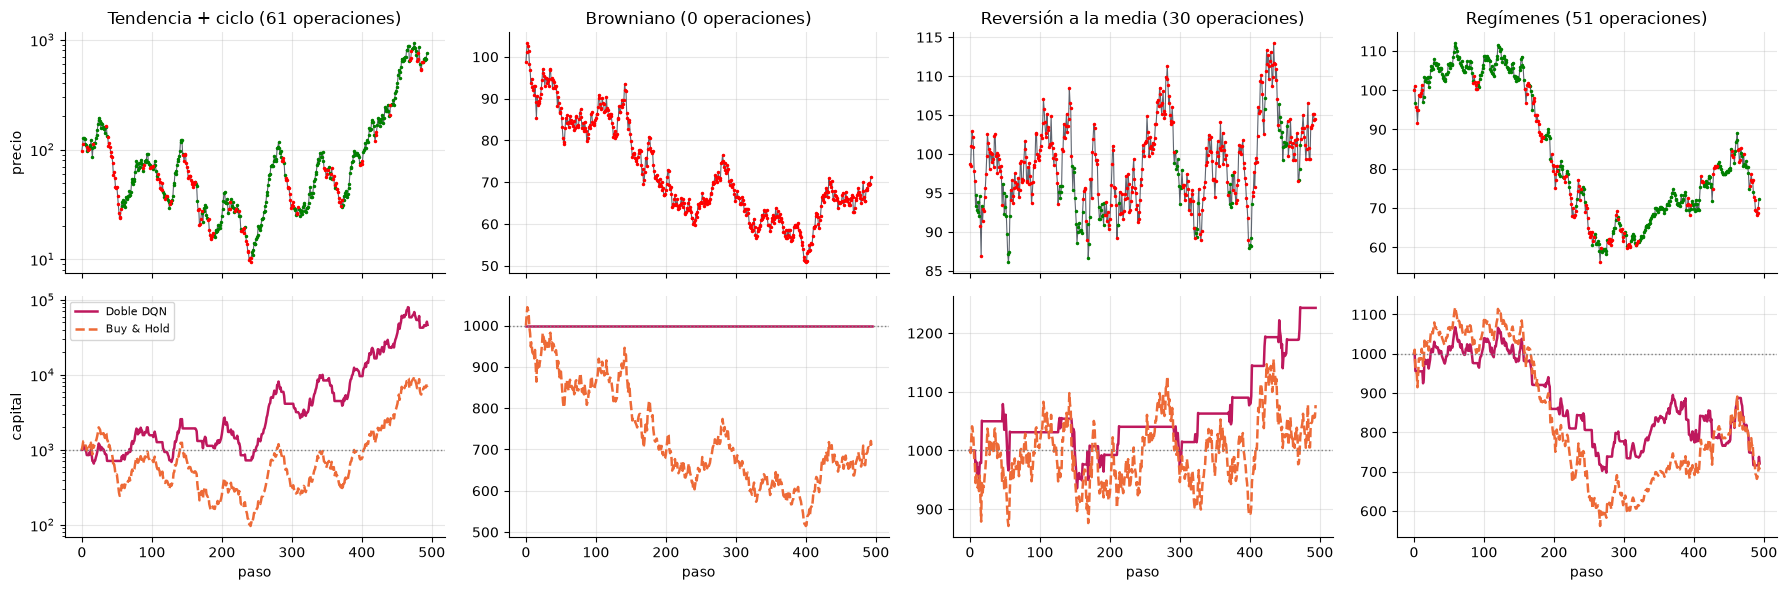

In [21]:
fig, axs = plt.subplots(2, 4, figsize=(18, 6), sharex=True)
for k, g in enumerate(GENS):
    prices = TEST[g][0]
    run = runs_de("Doble DQN", g)[0]
    bal, pos, ops = run_episode(prices, politica_desde(run["pol"]))
    bal_bh, _, _ = run_episode(prices, BASELINES["Buy & Hold"](0))
    p = prices[5:-1]
    axs[0, k].plot(p, color="#1b2433", lw=0.8, alpha=0.7)
    axs[0, k].plot(np.where(pos == 1, p, np.nan), ".", color="green", ms=3)
    axs[0, k].plot(np.where(pos == 0, p, np.nan), ".", color="red", ms=3)
    axs[0, k].set_title(f"{g} ({ops} operaciones)")
    axs[1, k].plot(bal, color=COLORES["Doble DQN"], lw=1.8, label="Doble DQN")
    axs[1, k].plot(bal_bh, color=COLORES["Buy & Hold"], lw=1.8, ls="--", label="Buy & Hold")
    axs[1, k].axhline(1000, color="gray", ls=":", lw=1)
    axs[1, k].set_xlabel("paso")
    if g == "Tendencia + ciclo":
        axs[0, k].set_yscale("log")
        axs[1, k].set_yscale("log")
axs[0, 0].set_ylabel("precio")
axs[1, 0].set_ylabel("capital")
axs[1, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGS / "episodios_ejemplo.png", bbox_inches="tight")
plt.show()

**Lectura de la política aprendida**

- ***Tendencia + ciclo*** (*momentum* con histéresis): estando fuera, solo compra cuando la tendencia es positiva (la fila «fuera» es verde a la derecha de ≈ 0). Estando dentro, mantiene hasta que la tendencia cae por debajo de ≈ −0,08 (la fila «dentro» se extiende más a la izquierda). Es la estrategia esperada y la misma que aprendieron Q-Learning, SARSA y Monte Carlo.
- ***Browniano***: la fila «fuera» es casi blanca, es decir, no compra. La fila «dentro» es verde en casi todo el rango, pero casi nunca está dentro, así que es irrelevante. La política efectiva es **quedarse fuera**, que es lo racional (la deriva logarítmica es negativa).
- ***Reversión a la media*** (*contrarian*): compra con tendencias claramente negativas (por debajo de ≈ −0,02 a −0,04) y mantiene hasta que la tendencia pasa a ser ligeramente positiva (≈ +0,01 a +0,03), donde la fila «dentro» se vuelve blanca, es decir, vende. Compra en los valles y vende cuando el precio se ha recuperado, como se esperaba.
- ***Regímenes***: la fila «dentro» es una meseta verde en el rango central y blanca en los extremos: **vende ante movimientos muy bruscos**, que suelen indicar el régimen bajista (más volátil). La fila «fuera» es casi blanca, así que apenas compra. Es la misma meseta que en la práctica 1; las semillas discrepan algo en los extremos (los verdes claros).
- Las **cuatro variantes** aprenden políticas casi idénticas en *tendencia + ciclo* y en *reversión a la media*; en el episodio de ejemplo se ve la misma conducta (dentro en las fases alcistas del ciclo, compras en los valles de la reversión y ninguna operación en el browniano).

### 8.2 Sobreestimación de $Q$: DQN frente a red objetivo y Doble DQN

La motivación de Doble DQN es que el operador $\max$ **sobreestima** $Q$ cuando las estimaciones tienen ruido, y aquí el ruido es enorme (la señal es de décimas de punto frente a movimientos del 1–10 % por paso). Para verlo hay que mirar los mercados donde el valor real del mejor comportamiento es pequeño y usar un $\gamma$ alto, que es cuando el valor estimado del estado siguiente pesa más. Se entrenan DQN, DQN + red objetivo y Doble DQN con $\gamma = 0{,}99$ (el resto de hiperparámetros, los elegidos) y se registra el **valor medio estimado del estado siguiente** en cada lote, en unidades de desviación de la recompensa: si crece sin que el rendimiento lo respalde, es sobreestimación.

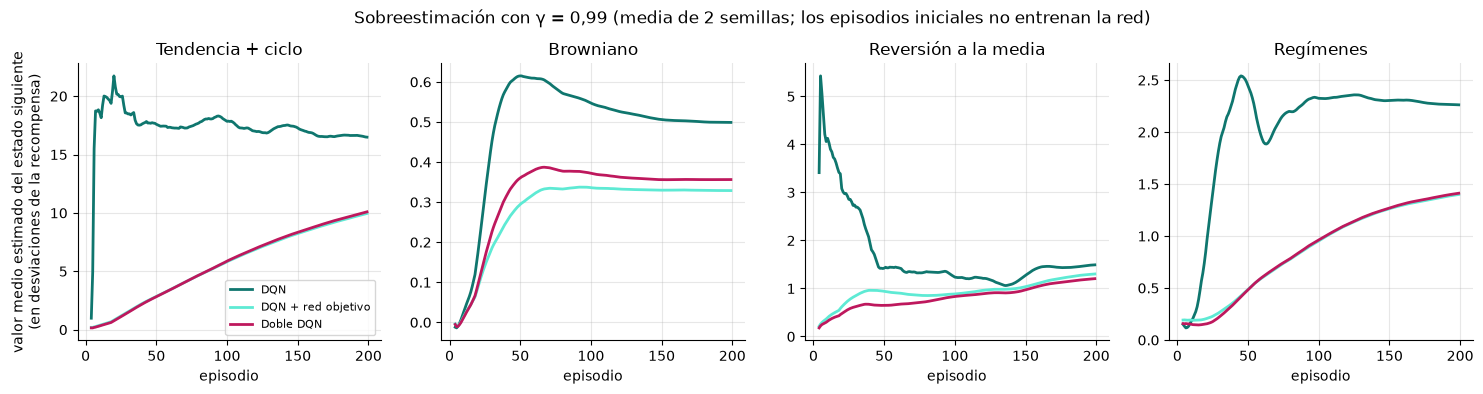

variante,DQN,DQN + red objetivo,Doble DQN
Q estimado al final del entrenamiento,,,
Browniano,0.50,0.33,0.36
Regímenes,2.28,1.36,1.37
Reversión a la media,1.46,1.23,1.15
Tendencia + ciclo,16.58,9.37,9.51


variante,DQN,DQN + red objetivo,Doble DQN
"log-retorno en test con γ = 0,99",,,
Browniano,-0.031,-0.029,-0.033
Regímenes,-0.034,-0.055,-0.061
Reversión a la media,0.204,0.202,0.187
Tendencia + ciclo,6.199,6.181,6.128


In [22]:
GAMMA_ALTO, VARS_SOBRE = 0.99, ["DQN", "DQN + red objetivo", "Doble DQN"]
f_sobre = CACHE / "runs_sobreestimacion.joblib"
if RECOMPUTE or not f_sobre.exists():
    RUNS_SOBRE = ejecutar([dict(gen=g, params={**MEJORES_PARAMS[g], "gamma": GAMMA_ALTO}, n_ep=N_EP_FINAL, semilla=s, eval_cada=EVAL_CADA, variante=v)
                           for v in VARS_SOBRE for g in GENS for s in SEMILLAS_EXTRA], "sobreestimación (γ = 0,99)")
    dump(RUNS_SOBRE, f_sobre)
else:
    RUNS_SOBRE = load(f_sobre)


def suavizar(x, k=15):
    x = np.asarray(x, dtype=float)
    return np.array([np.nanmean(x[max(0, i - k + 1):i + 1]) if np.isfinite(x[max(0, i - k + 1):i + 1]).any() else np.nan for i in range(len(x))])


fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, g in zip(axs, GENS):
    for v in VARS_SOBRE:
        q = np.mean([suavizar(r["hist"]["q"]) for r in runs_de(v, g, RUNS_SOBRE)], axis=0)
        ax.plot(q, color=COLORES[v], lw=2, label=v)
    ax.set_title(g)
    ax.set_xlabel("episodio")
axs[0].set_ylabel("valor medio estimado del estado siguiente\n(en desviaciones de la recompensa)")
axs[0].legend(fontsize=8)
fig.suptitle(f"Sobreestimación con γ = 0,99 (media de {len(SEMILLAS_EXTRA)} semillas; los episodios iniciales no entrenan la red)", y=1.03)
plt.savefig(FIGS / "sobreestimacion.png", bbox_inches="tight")
plt.show()

EVAL_SOBRE = evaluar_todos(RUNS_SOBRE)
filas = []
for v in VARS_SOBRE:
    for g in GENS:
        idx = [i for i, r in enumerate(RUNS_SOBRE) if r["variante"] == v and r["gen"] == g]
        d = [EVAL_SOBRE[i] for i in idx]
        filas.append({"variante": v, "mercado": g, "Q estimado (últimos 50 ep.)": np.mean([np.nanmean(RUNS_SOBRE[i]["hist"]["q"][-50:]) for i in idx]),
                      "log-ret. test": np.mean([x["log_ret"].mean() for x in d]), "± entre semillas": np.std([x["log_ret"].mean() for x in d]),
                      "operaciones": np.mean([x["trades"].mean() for x in d])})
sobre = pd.DataFrame(filas)
display(sobre.pivot(index="mercado", columns="variante", values="Q estimado (últimos 50 ep.)").round(2).rename_axis("Q estimado al final del entrenamiento")[VARS_SOBRE])
display(sobre.pivot(index="mercado", columns="variante", values="log-ret. test").round(3).rename_axis("log-retorno en test con γ = 0,99")[VARS_SOBRE])

**Lectura**

- **Qué se mide.** Esa cantidad es el valor máximo (o el evaluado por $Q'$ en Doble DQN) del estado siguiente. En el **browniano** el valor real de la mejor política es ≈ 0 (no operar), así que cualquier estimación positiva es sobreestimación: DQN estima **0,50**, la red objetivo **0,33** y Doble DQN **0,36**. En los otros mercados el valor real no es cero y no se conoce, pero el patrón es el mismo: sin red objetivo las estimaciones son claramente mayores (en *regímenes* 2,28 frente a 1,36–1,37; en *reversión* 1,46 frente a 1,15–1,23; en *tendencia + ciclo* 16,6 frente a 9,4–9,5).
- **Casi todo el efecto viene de la red objetivo $Q'$, no del estimador doble.** DQN + red objetivo y Doble DQN dan estimaciones casi iguales (0,33 y 0,36; 1,36 y 1,37; 1,23 y 1,15; 9,37 y 9,51). Con esta red pequeña y una señal tan ruidosa, congelar el objetivo cada $k$ pasos estabiliza mucho, y separar la elección de la acción de su evaluación añade poco encima.
- **La sobreestimación no se traduce en peor política, y reducirla tampoco mejora el rendimiento.** Con $\gamma = 0{,}99$ el rendimiento en test es parecido con las tres variantes (en *reversión* 0,204, 0,202 y 0,187; en *regímenes* −0,034, −0,055 y −0,061; en *tendencia + ciclo* 6,20, 6,18 y 6,13), con solo 2 semillas y diferencias del tamaño de su dispersión, así que no hay ganador. La política depende de las **diferencias** entre las $Q$ de las acciones, no de su nivel: si se sobreestima por igual el valor de «comprar» y el de «mantener», la acción elegida es la misma. Esto coincide con lo que vimos con Double Q-Learning en la práctica 1, que no se distinguía del ruido entre semillas.

### 8.3 Estado ampliado: lo que una red puede usar sin discretizar

En la práctica 1 la mejora más grande vino de ampliar el estado con la **volatilidad reciente** (desviación típica de los 10 últimos log-retornos) y la **distancia a la media de 20 pasos** (`ExtendedTradingEnv`): Q-Learning pasó de +17 % a +37 % en reversión a la media y de +4 % a +17 % en regímenes. Con una tabla eso exigía discretizar cuatro variables (200 estados); una red las recibe tal cual, así que es un experimento natural para DQN. Se entrena el **Doble DQN** con la misma configuración y la misma red, solo con cuatro entradas en vez de dos.

In [23]:
f_ext = CACHE / "runs_estado_ampliado.joblib"
if RECOMPUTE or not f_ext.exists():
    RUNS_EXT = ejecutar([dict(gen=g, params=MEJORES_PARAMS[g], n_ep=N_EP_FINAL, semilla=s, eval_cada=EVAL_CADA, variante="Doble DQN", env_cls=ExtendedTradingEnv)
                         for g in GENS for s in SEMILLAS_FINAL], "estado ampliado")
    dump(RUNS_EXT, f_ext)
else:
    RUNS_EXT = load(f_ext)
EVAL_EXT = evaluar_todos(RUNS_EXT)
f_coste_ext = CACHE / "coste_ms_ampliado.csv"
if RECOMPUTE or not f_coste_ext.exists():
    pd.DataFrame([{"gen": g, "ms": coste_episodio("Doble DQN", g, MEJORES_PARAMS[g], env_cls=ExtendedTradingEnv)} for g in GENS]).to_csv(f_coste_ext, index=False)
COSTE_EXT = pd.read_csv(f_coste_ext).set_index("gen").ms.to_dict()

filas = [fila([EVAL_EXT[i] for i, r in enumerate(RUNS_EXT) if r["gen"] == g], "Doble DQN (estado ampliado)", g, [r for r in RUNS_EXT if r["gen"] == g], COSTE_EXT[g]) for g in GENS]
ext = pd.DataFrame(filas).set_index(["Generador", "Agente"])
ext.to_csv("resultados_dqn_estado_ampliado.csv")
comp = pd.DataFrame({
    "Q-Learning (tabular)": [prac1.loc[(g, "Q-Learning"), "Log-ret. medio"] for g in GENS],
    "Q-Learning estado ampliado (tabular)": [prac1.loc[(g, "Q-Learning (estado ampliado)"), "Log-ret. medio"] for g in GENS],
    "Doble DQN": [tabla.loc[(g, "Doble DQN"), "Log-ret. medio"] for g in GENS],
    "Doble DQN estado ampliado": [ext.loc[(g, "Doble DQN (estado ampliado)"), "Log-ret. medio"] for g in GENS],
    "Buy & Hold": [tabla.loc[(g, "Buy & Hold"), "Log-ret. medio"] for g in GENS]}, index=GENS)
print("Log-retorno medio en test:")
display(comp.round(3))
display(ext[["Log-ret. medio", "Ret. geométrico (%)", "% series > B&H", "Sharpe", "Operaciones", "Std log-ret. entre semillas", "Episodios hasta convergencia", "ms/episodio", "Tiempo hasta convergencia (s)"]].style.format(FMT, na_rep="—"))

Log-retorno medio en test:


,Q-Learning (tabular),Q-Learning estado ampliado (tabular),Doble DQN,Doble DQN estado ampliado,Buy & Hold
Tendencia + ciclo,6.338,6.579,6.241,6.609,3.316
Browniano,0.000,-0.006,-0.005,-0.019,-0.062
Reversión a la media,0.155,0.317,0.201,0.273,-0.005
Regímenes,0.040,0.154,0.008,0.130,-0.128


,,Log-ret. medio,Ret. geométrico (%),% series > B&H,Sharpe,Operaciones,Std log-ret. entre semillas,Episodios hasta convergencia,ms/episodio,Tiempo hasta convergencia (s)
Generador,Agente,,,,,,,,,
Tendencia + ciclo,Doble DQN (estado ampliado),6.609,"74,107.5",98,3.24,52.0,0.072,60,165,9.9
Browniano,Doble DQN (estado ampliado),-0.019,-1.9,52,-0.01,11.3,0.021,160,151,24.2
Reversión a la media,Doble DQN (estado ampliado),0.273,31.3,93,0.87,41.2,0.024,100,173,17.3
Regímenes,Doble DQN (estado ampliado),0.130,13.9,74,0.52,19.3,0.017,140,154,21.6


**Lectura**

- La red usa las dos variables nuevas **sin discretizar** y gana en tres mercados: *tendencia + ciclo* de 6,24 a **6,61** (más que el Q-Learning tabular ampliado, 6,58), *reversión a la media* de 0,201 a **0,273** (+31 % geométrico) y *regímenes* de 0,008 a **0,130** (+14 %), que supera con holgura a *buy & hold* (−0,128).
- **El estado importa más que la variante.** Ampliar la información mejora el resultado más que cualquier cambio de algoritmo de la sección 7 (la mejor variante base saca 0,201 en *reversión*; ampliar el estado, 0,273). Es la misma conclusión de la práctica 1.
- **Pero tampoco supera a la tabla ampliada** en *reversión* (0,273 frente a 0,317) ni en *regímenes* (0,130 frente a 0,154), con un estado de solo cuatro variables y una señal tan pequeña. La red se queda cerca, sin discretizar a mano, pero una tabla con 200 estados bien elegidos sigue siendo competitiva.
- **En el browniano empeora un poco** (−0,019, con 11 operaciones por episodio, frente a −0,005): con más variables la red tiene más capacidad para ajustarse al ruido y opera de más. Es el mismo efecto que con el estado ampliado tabular (−0,006).
- **Coste:** el episodio cuesta 150–175 ms, parecido al del estado básico, porque el tiempo lo domina la actualización de la red.

## 9. Conclusiones y limitaciones

**Contraste con las hipótesis de partida**

1. ***Tendencia + ciclo*: cumplida a medias.** DQN aprende el *momentum* con histéresis, pero rinde algo por debajo de los tabulares (6,09–6,26 frente a 6,32–6,52). Lo que sí se cumple es que **aprende con muchos menos episodios**: converge en 60 frente a 300–500.
2. ***Reversión a la media*: cumplida.** La curva de aprendizaje es la más inestable (bandas anchas entre semillas, y alguna configuración «se apaga» y deja de operar). El resultado final es bueno: 0,175–0,201, comparable con SARSA (0,203) y entre Q-Learning (0,155) y Monte Carlo (0,238).
3. ***Browniano* y *regímenes*: en parte.** En el browniano **no sobreopera** (0–0,7 operaciones por episodio). En regímenes saca +3 % (DQN) con una variación entre semillas del mismo tamaño que la media: no concluyente.
4. **Variantes: cumplida.** Doble DQN **estabiliza** el aprendizaje (reduce la variación entre semillas de 0,182 a 0,101, de 0,045 a 0,020 y de 0,040 a 0,011) sin mejorar de forma clara la media. La sobreestimación existe, pero casi todo el efecto lo da la **red objetivo**, y no empeora la política. El duelo no aporta con 3 acciones.
5. **Tiempo: cumplida.** Menos episodios pero 12–25 veces más caros: en segundos, DQN converge **más despacio** que los algoritmos tabulares (por ejemplo 9 s frente a 2,4–4,8 s en *tendencia + ciclo*).

**Conclusiones**

- En un problema con un estado de solo dos variables, **DQN no supera a Q-Learning, SARSA ni Monte Carlo**: los iguala en los mercados difíciles y queda ligeramente por debajo en el fácil, a un coste de cómputo mucho mayor. Una tabla de 10–20 intervalos ya describe casi cualquier función de la tendencia.
- Su ventaja aparece cuando **el estado crece**: con volatilidad y distancia a la media, la red las usa sin discretizar y mejora mucho (+0,37 en *tendencia + ciclo*, +0,07 en *reversión*, +0,12 en *regímenes*). Aun así, la tabla ampliada sigue siendo igual o algo mejor.
- Como en la práctica 1, **pesan más la información que tiene el estado y los hiperparámetros** (sobre todo $\gamma$ y la tasa de aprendizaje decreciente) **que la variante concreta** del algoritmo.
- Ningún mercado sin señal se explota: los agentes aprenden a no operar o casi (browniano), que es lo racional.

**Limitaciones**

- Los mercados son **sintéticos** y el entorno es de todo o nada con una comisión fija; los resultados no se pueden extrapolar a datos reales.
- Solo **5 semillas** por variante y 100 series de test: las diferencias de media menores que la desviación entre semillas (casi todas entre variantes, y en *regímenes* todas) no son concluyentes.
- **El ajuste fue corto:** 10 configuraciones por mercado con 100 episodios, y se ajustó el DQN básico y luego se reutilizó para las demás variantes. Otras variantes podrían preferir otros hiperparámetros.
- DQN se entrenó con **200 episodios** frente a 3000 de los tabulares. Es justo en datos por episodio, pero no igualaría el presupuesto de cómputo, que favorece a las tablas.
- En el browniano, $\gamma = 0$ hace que las variantes sean idénticas por construcción, así que ese mercado no sirve para comparar Doble DQN con DQN. La comparación de estimaciones de $Q$ se hace por eso con $\gamma = 0{,}99$ fijo.